# Generative Project — Milestone 1: Setup & Dataset

**Author:** Tanmayi Shurpali

**Goal of this milestone:** get everything in place for a text-to-image project built on Stable Diffusion. By the end of this notebook I have

1. a chosen and justified dataset (**MS-COCO 2017 Captions**),
2. a cleaned, preprocessed set of **~3,000 image–caption pairs** (configurable between 1k and 5k), split into train / val / test,
3. a working, version-logged **PyTorch + Diffusers + CLIP** environment, and
4. a validated **text → embedding pipeline** whose output is exactly what the Stable Diffusion U-Net consumes (checked numerically against the SD text encoder, and end-to-end by generating images from my own embeddings).

### Contents
| # | Section | Milestone task |
|---|---|---|
| 1 | Environment setup | Task 3 |
| 2 | Choosing the dataset | Task 1 |
| 3 | Sampling candidates & downloading | Task 1 |
| 4 | Cleaning images and captions | Task 2 |
| 5 | Image preprocessing (512×512) | Task 2 |
| 6 | CLIP-based alignment filtering | Task 2 |
| 7 | Splits & export | Task 2 |
| 8 | Text → embedding pipeline | Task 4 |
| 9 | Validating the pipeline | Task 4 |
| 10 | Do the embeddings mean anything? (retrieval, t-SNE, search) | Task 4 |
| 11 | End-to-end smoke test with Diffusers | Tasks 3 + 4 |
| 12 | Summary, decisions & next steps | — |

### How to run
* Designed for **Google Colab with a GPU runtime** (T4 is enough): *Runtime → Change runtime type → T4 GPU*, then *Runtime → Run all*.
* Total runtime ≈ 15–25 min on a T4 (most of it is downloading). It also runs on CPU, just slower, and the Stable Diffusion smoke test is skipped automatically without a GPU.
* Disk needed: ≈ 2 GB (annotation zip 241 MB, ~3.4k raw images, processed 512 px copies, model weights).
* Everything is controlled by one `Config` object in Section 1 — change `n_target_images` there to anything from 1,000 to 5,000.

## 1. Environment setup

PyTorch comes preinstalled on Colab, so I only install the Hugging Face stack on top of it. (Running locally: install PyTorch first from pytorch.org for your CUDA version, then run the cell below.)

* **diffusers** — Stable Diffusion pipelines, schedulers, U-Net/VAE
* **transformers** — CLIP model, tokenizer and processor
* **accelerate / safetensors** — fast, safe weight loading
* **ftfy** — the CLIP tokenizer uses it to fix broken unicode if it's installed
* **scikit-learn** — t-SNE for the embedding visualization

In [1]:
%pip install -q -U diffusers transformers accelerate safetensors ftfy scikit-learn

In [2]:
import os, io, re, json, math, time, random, shutil, zipfile, platform, unicodedata, textwrap, warnings
from dataclasses import dataclass, asdict
from pathlib import Path
from collections import Counter
from concurrent.futures import ThreadPoolExecutor, as_completed

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import requests
from PIL import Image, ImageOps
from tqdm.auto import tqdm

import torch
import torch.nn.functional as F
import transformers
import diffusers
from transformers import CLIPModel, CLIPProcessor, CLIPTokenizer, CLIPTextModel
from diffusers import StableDiffusionPipeline

warnings.filterwarnings("ignore", category=FutureWarning)
transformers.logging.set_verbosity_error()
pd.set_option("display.max_colwidth", 120)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

NOTEBOOK_START = time.time()

In [3]:
def seed_everything(seed: int) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    os.environ["PYTHONHASHSEED"] = str(seed)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else
                      "mps" if torch.backends.mps.is_available() else "cpu")

ENV_INFO = {
    "python": platform.python_version(),
    "platform": platform.platform(),
    "torch": torch.__version__,
    "cuda_available": torch.cuda.is_available(),
    "cuda_version": torch.version.cuda,
    "device": str(DEVICE),
    "gpu": torch.cuda.get_device_name(0) if torch.cuda.is_available() else None,
    "gpu_memory_gb": round(torch.cuda.get_device_properties(0).total_memory / 1e9, 1) if torch.cuda.is_available() else None,
    "diffusers": diffusers.__version__,
    "transformers": transformers.__version__,
    "numpy": np.__version__,
    "pandas": pd.__version__,
    "pillow": Image.__version__,
}
for k, v in ENV_INFO.items():
    print(f"{k:>15}: {v}")

if DEVICE.type != "cuda":
    print("\nNo CUDA GPU found: everything still runs, but CLIP encoding is slower and the SD smoke test (Section 11) will be skipped.")

         python: 3.13.16
       platform: Linux-6.6.159+-x86_64-with-glibc2.39
          torch: 2.11.0+cu130
 cuda_available: True
   cuda_version: 13.0
         device: cuda
            gpu: Tesla T4
  gpu_memory_gb: 15.6
      diffusers: 0.42.1
   transformers: 5.22.1
          numpy: 2.4.6
         pandas: 2.2.3
         pillow: 11.3.0


### Configuration
All the knobs for the milestone live in one place so the run is reproducible and easy to change. The reasoning behind each threshold is explained in the section where it's used.

In [4]:
@dataclass
class Config:
    seed: int = 42

    # --- dataset ---
    coco_split: str = "train2017"
    n_candidates: int = 3600          # oversample: cleaning + filtering will drop some
    n_target_images: int = 3000       # final number of image-caption pairs (milestone asks for 1k-5k)
    min_captions_per_image: int = 3   # after cleaning, an image must keep at least this many captions

    # --- image rules ---
    min_side: int = 400               # avoid upscaling small images by more than ~1.3x to reach 512
    max_aspect_ratio: float = 2.0     # very wide/tall images lose too much content in a square crop
    min_pixel_std: float = 8.0        # near-uniform (blank) images
    image_size: int = 512             # native resolution of Stable Diffusion v1.5
    dhash_size: int = 16              # 16x16 difference hash = 256 bits
    near_dup_hamming: int = 12        # <=12/256 differing bits -> near-duplicate

    # --- caption rules ---
    min_words: int = 5
    max_words: int = 40
    max_non_ascii_frac: float = 0.05
    max_tokens: int = 77              # CLIP context length, including BOS/EOS

    # --- CLIP models ---
    clip_model_id: str = "openai/clip-vit-large-patch14"           # the text encoder SD v1.x was trained with
    sd_model_id: str = "stable-diffusion-v1-5/stable-diffusion-v1-5"
    clip_image_drop_pct: float = 5.0  # drop the worst-aligned 5% of images
    clip_caption_drop_pct: float = 1.0  # drop the worst-aligned 1% of individual captions

    # --- misc ---
    split_fracs: tuple = (0.8, 0.1, 0.1)
    batch_size: int = 64
    download_workers: int = 32
    run_sd_smoke_test: bool = True

CFG = Config()
assert 1000 <= CFG.n_target_images <= 5000, "Milestone requires 1k-5k pairs"
assert CFG.n_candidates > CFG.n_target_images
seed_everything(CFG.seed)

ROOT       = Path("milestone1_artifacts")
RAW_DIR    = ROOT / "raw"
RAW_IMG    = RAW_DIR / "images"
PROC_DIR   = ROOT / "processed"
PROC_IMG   = PROC_DIR / "images"
EMB_DIR    = ROOT / "embeddings"
FIG_DIR    = ROOT / "figures"
for d in [RAW_IMG, PROC_IMG, EMB_DIR, FIG_DIR]:
    d.mkdir(parents=True, exist_ok=True)

def savefig(name: str) -> None:
    plt.savefig(FIG_DIR / f"{name}.png", bbox_inches="tight", dpi=130)

FUNNEL = []   # (stage, number of images) — filled as the pipeline runs
def log_stage(stage: str, n: int) -> None:
    FUNNEL.append((stage, int(n)))
    print(f"[funnel] {stage:<45} {n:>8,}")

print(json.dumps(asdict(CFG), indent=2))

{
  "seed": 42,
  "coco_split": "train2017",
  "n_candidates": 3600,
  "n_target_images": 3000,
  "min_captions_per_image": 3,
  "min_side": 400,
  "max_aspect_ratio": 2.0,
  "min_pixel_std": 8.0,
  "image_size": 512,
  "dhash_size": 16,
  "near_dup_hamming": 12,
  "min_words": 5,
  "max_words": 40,
  "max_non_ascii_frac": 0.05,
  "max_tokens": 77,
  "clip_model_id": "openai/clip-vit-large-patch14",
  "sd_model_id": "stable-diffusion-v1-5/stable-diffusion-v1-5",
  "clip_image_drop_pct": 5.0,
  "clip_caption_drop_pct": 1.0,
  "split_fracs": [
    0.8,
    0.1,
    0.1
  ],
  "batch_size": 64,
  "download_workers": 32,
  "run_sd_smoke_test": true
}


### Environment smoke test
Before touching any data I check that the three required libraries actually work together: a tensor op on the device, a CLIP tokenizer round trip, and a Diffusers scheduler (a small object that needs no weights). I also freeze the environment to `environment.json` and `requirements.txt` so the project can be rebuilt later.

In [5]:
from diffusers import DDIMScheduler

# 1) PyTorch on the selected device
a = torch.randn(512, 512, device=DEVICE)
b = a @ a.T
assert torch.isfinite(b).all()
print(f"PyTorch matmul on {DEVICE}: OK  (result shape {tuple(b.shape)})")

# 2) CLIP tokenizer (downloads ~2 MB of vocab files)
tokenizer = CLIPTokenizer.from_pretrained(CFG.clip_model_id)
ids = tokenizer("a photo of a cat")["input_ids"]
print(f"CLIP tokenizer: OK  -> {tokenizer.convert_ids_to_tokens(ids)}")

# 3) Diffusers scheduler
sched = DDIMScheduler(num_train_timesteps=1000, beta_schedule="scaled_linear")
sched.set_timesteps(25)
print(f"Diffusers DDIM scheduler: OK  -> first timesteps {sched.timesteps[:5].tolist()}")

(ROOT / "environment.json").write_text(json.dumps(ENV_INFO, indent=2))
(ROOT / "requirements.txt").write_text("\n".join([
    f"torch=={torch.__version__.split('+')[0]}",
    f"diffusers=={diffusers.__version__}",
    f"transformers=={transformers.__version__}",
    "accelerate", "safetensors", "ftfy", "scikit-learn",
    f"numpy=={np.__version__}", f"pandas=={pd.__version__}", f"pillow=={Image.__version__}",
    "matplotlib", "requests", "tqdm",
]) + "\n")
print("\nSaved environment.json and requirements.txt")
del a, b

PyTorch matmul on cuda: OK  (result shape (512, 512))


tokenizer_config.json:   0%|          | 0.00/905 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/961k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/525k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/2.22M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/389 [00:00<?, ?B/s]

CLIP tokenizer: OK  -> ['<|startoftext|>', 'a</w>', 'photo</w>', 'of</w>', 'a</w>', 'cat</w>', '<|endoftext|>']
Diffusers DDIM scheduler: OK  -> first timesteps [960, 920, 880, 840, 800]

Saved environment.json and requirements.txt


## 2. Choosing the dataset

The milestone allows COCO, Flickr30k, or a curated subset. I compared them on what actually matters for a text-to-image project:

| | **MS-COCO 2017 Captions** | **Flickr30k** | **Own curated subset** |
|---|---|---|---|
| Size | ~118k train images, ~590k captions | ~31k images, ~155k captions | whatever I collect |
| Captions per image | 5, human-written | 5, human-written | usually 1 |
| Content | everyday scenes, 80 object categories, many objects per image | mostly people doing everyday activities | narrow domain |
| Access | annotations in one JSON; **every image has its own public URL** | access form / unofficial mirrors | manual work |
| Use in generative research | standard benchmark for text-to-image (e.g. FID on COCO captions) | mostly retrieval / captioning | none |

**Decision: MS-COCO 2017 (train split), ~3,000 images.**

* **Per-image URLs** mean I can download only the images I need (~0.5 GB) instead of the full 18 GB archive.
* **Five captions per image** is a big advantage: I can pick the caption that best matches each image (using CLIP), and I can use the others to evaluate my embeddings with retrieval metrics.
* COCO's diversity (people, animals, food, vehicles, indoor and outdoor scenes) gives a much better test of a text→image model than Flickr30k's people-heavy content.
* License: annotations are CC BY 4.0; images keep their original Flickr licenses, so I use them only for coursework/research and don't redistribute them.

So what I build is effectively a **curated COCO subset**: sampled from COCO, then cleaned and filtered with explicit rules.

In [6]:
ANN_URL    = "http://images.cocodataset.org/annotations/annotations_trainval2017.zip"
ANN_ZIP    = RAW_DIR / "annotations_trainval2017.zip"
CAP_MEMBER = f"annotations/captions_{CFG.coco_split}.json"
CAP_JSON   = RAW_DIR / CAP_MEMBER

def download_file(url: str, dest: Path, chunk: int = 1 << 20) -> Path:
    # Stream a large file to disk with a progress bar; resumable in the sense that a finished file is skipped.
    if dest.exists() and dest.stat().st_size > 0:
        print(f"Already downloaded: {dest.name} ({dest.stat().st_size / 1e6:.0f} MB)")
        return dest
    tmp = dest.with_suffix(dest.suffix + ".part")
    with requests.get(url, stream=True, timeout=60) as r:
        r.raise_for_status()
        total = int(r.headers.get("content-length", 0))
        with open(tmp, "wb") as f, tqdm(total=total, unit="B", unit_scale=True, desc=dest.name) as bar:
            for block in r.iter_content(chunk):
                f.write(block)
                bar.update(len(block))
    tmp.rename(dest)
    return dest

if not CAP_JSON.exists():
    download_file(ANN_URL, ANN_ZIP)
    with zipfile.ZipFile(ANN_ZIP) as zf:
        zf.extract(CAP_MEMBER, RAW_DIR)   # only the captions file, not the 450 MB instances file
print(f"Captions file: {CAP_JSON}  ({CAP_JSON.stat().st_size / 1e6:.1f} MB)")

annotations_trainval2017.zip:   0%|          | 0.00/253M [00:00<?, ?B/s]

Captions file: milestone1_artifacts/raw/annotations/captions_train2017.json  (91.9 MB)


In [7]:
with open(CAP_JSON) as f:
    coco = json.load(f)

images_df = (pd.DataFrame(coco["images"])[["id", "file_name", "coco_url", "height", "width"]]
               .rename(columns={"id": "image_id"}))
caps_df = (pd.DataFrame(coco["annotations"])[["id", "image_id", "caption"]]
             .rename(columns={"id": "caption_id"}))
del coco

images_df["n_captions"] = images_df["image_id"].map(caps_df.groupby("image_id").size()).fillna(0).astype(int)
images_df["min_side"]   = images_df[["height", "width"]].min(axis=1)
images_df["aspect"]     = images_df[["height", "width"]].max(axis=1) / images_df["min_side"]
caps_df["n_words"]      = caps_df["caption"].str.split().str.len()

print(f"COCO {CFG.coco_split}: {len(images_df):,} images, {len(caps_df):,} captions")
print(f"Captions per image: {images_df.n_captions.value_counts().sort_index().to_dict()}")
print(f"Words per caption: mean {caps_df.n_words.mean():.1f}, median {caps_df.n_words.median():.0f}, "
      f"min {caps_df.n_words.min()}, max {caps_df.n_words.max()}")
log_stage(f"COCO {CFG.coco_split} images", len(images_df))
caps_df.sample(5, random_state=CFG.seed)

COCO train2017: 118,287 images, 591,753 captions
Captions per image: {5: 117972, 6: 312, 7: 3}
Words per caption: mean 10.5, median 10, min 5, max 49
[funnel] COCO train2017 images                          118,287


,caption_id,image_id,caption,n_words
264066,533860,449919,Two young men sitting on a bench and a lady standing next to them,14
31867,93313,19783,Seagulls in flight with a person feeding one with a lighthouse in the distance.,14
279034,82787,574275,Three spotted furry animals gazing in a field.,8
258963,401809,184679,A white truck with a lamb sitting on it's flatbed.,10
91524,148795,468736,A plate of pasta with meat and broccoli together,9


### A first look at the full corpus
Before sampling, I want to know what "normal" looks like so my filtering thresholds are grounded in the data rather than guessed.

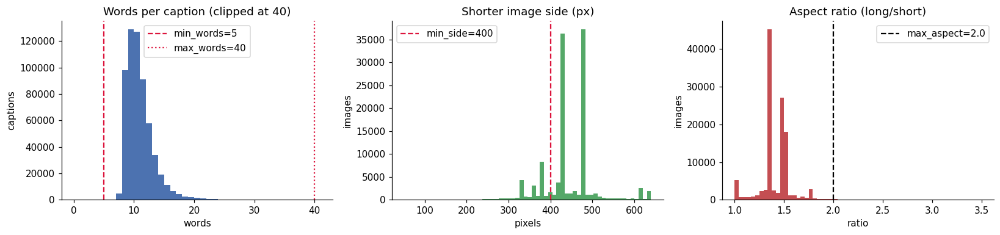

Images with min side < 400px: 18.6%
Images with aspect > 2.0: 1.0%
Captions with < 5 words: 0.00%


In [8]:
fig, ax = plt.subplots(1, 3, figsize=(15, 3.6))

ax[0].hist(caps_df.n_words.clip(upper=40), bins=np.arange(0, 42), color="#4C72B0")
ax[0].axvline(CFG.min_words, color="crimson", ls="--", label=f"min_words={CFG.min_words}")
ax[0].axvline(CFG.max_words, color="crimson", ls=":",  label=f"max_words={CFG.max_words}")
ax[0].set(title="Words per caption (clipped at 40)", xlabel="words", ylabel="captions")
ax[0].legend()

ax[1].hist(images_df.min_side, bins=60, color="#55A868")
ax[1].axvline(CFG.min_side, color="crimson", ls="--", label=f"min_side={CFG.min_side}")
ax[1].set(title="Shorter image side (px)", xlabel="pixels", ylabel="images")
ax[1].legend()

ax[2].hist(images_df.aspect.clip(upper=3.5), bins=60, color="#C44E52")
ax[2].axvline(CFG.max_aspect_ratio, color="black", ls="--", label=f"max_aspect={CFG.max_aspect_ratio}")
ax[2].set(title="Aspect ratio (long/short)", xlabel="ratio", ylabel="images")
ax[2].legend()

plt.tight_layout(); savefig("01_full_corpus_eda"); plt.show()

print(f"Images with min side < {CFG.min_side}px: {(images_df.min_side < CFG.min_side).mean():.1%}")
print(f"Images with aspect > {CFG.max_aspect_ratio}: {(images_df.aspect > CFG.max_aspect_ratio).mean():.1%}")
print(f"Captions with < {CFG.min_words} words: {(caps_df.n_words < CFG.min_words).mean():.2%}")

## 3. Sampling candidates & downloading

The COCO JSON already contains each image's width and height, so I apply the cheap **metadata rules first** (shorter side ≥ 400 px, aspect ratio ≤ 2, exactly 5 captions) and only download images that can pass. Then I randomly sample **3,600 candidates** — 20% more than the 3,000 I need, because cleaning and CLIP filtering will remove some.

A uniform random sample (fixed seed) keeps COCO's natural category mix and makes the selection reproducible.

In [9]:
eligible = images_df[
    (images_df.min_side >= CFG.min_side) &
    (images_df.aspect <= CFG.max_aspect_ratio) &
    (images_df.n_captions >= 5)
]
log_stage("pass metadata rules", len(eligible))

cand_df = eligible.sample(n=CFG.n_candidates, random_state=CFG.seed).reset_index(drop=True)
cand_caps = caps_df[caps_df.image_id.isin(cand_df.image_id)].copy().reset_index(drop=True)
log_stage("random candidates", len(cand_df))
print(f"Candidate captions: {len(cand_caps):,}")

[funnel] pass metadata rules                             96,336
[funnel] random candidates                                3,600
Candidate captions: 18,012


In [10]:
def fetch_image(row) -> tuple:
    dest = RAW_IMG / row.file_name
    if dest.exists() and dest.stat().st_size > 0:
        return row.image_id, True, "cached"
    err = ""
    for attempt in range(3):
        try:
            r = requests.get(row.coco_url, timeout=30)
            r.raise_for_status()
            dest.write_bytes(r.content)
            return row.image_id, True, "ok"
        except Exception as e:
            err = repr(e)
            time.sleep(1 + attempt)
    return row.image_id, False, err

t0 = time.time()
results = []
with ThreadPoolExecutor(max_workers=CFG.download_workers) as pool:
    futures = [pool.submit(fetch_image, row) for row in cand_df.itertuples()]
    for fut in tqdm(as_completed(futures), total=len(futures), desc="Downloading images"):
        results.append(fut.result())

dl = pd.DataFrame(results, columns=["image_id", "ok", "status"])
failed = dl[~dl.ok]
print(f"Downloaded in {time.time() - t0:.0f}s — status counts: {dl.status.where(dl.ok, 'failed').value_counts().to_dict()}")
if len(failed):
    print("Failures (first 5):"); print(failed.head())

cand_df = cand_df[cand_df.image_id.isin(dl[dl.ok].image_id)].reset_index(drop=True)
cand_df["raw_path"] = cand_df.file_name.map(lambda f: str(RAW_IMG / f))
log_stage("downloaded", len(cand_df))
print(f"Raw image folder size: {sum(p.stat().st_size for p in RAW_IMG.glob('*.jpg')) / 1e6:.0f} MB")

Downloaded in 47s — status counts: {'ok': 3600}
[funnel] downloaded                                       3,600
Raw image folder size: 628 MB


## 4. Cleaning

### 4.1 Images
A file that downloaded is not necessarily a usable training image. For every candidate I check:

| Check | Why it matters |
|---|---|
| Opens and passes `PIL.verify()` | truncated/corrupt JPEGs would crash a training DataLoader mid-epoch |
| EXIF orientation applied, converted to RGB | some COCO images are grayscale (mode `L`); the VAE expects 3 channels |
| Size rules re-checked on the real file | metadata can disagree with the actual file |
| Pixel standard deviation ≥ 8 | catches blank / near-uniform images |
| **Near-duplicate removal** with a 256-bit difference hash | COCO has a few near-identical shots; duplicates leak between train and test and waste capacity |

For near-duplicates I use a *difference hash* (dHash): shrink the image to 17×16 grayscale and record whether each pixel is brighter than its right neighbour. Two images whose hashes differ in ≤ 12 of 256 bits are treated as duplicates, and only the first is kept.

In [11]:
def dhash_bits(img: Image.Image, hash_size: int = 16) -> np.ndarray:
    g = np.asarray(img.convert("L").resize((hash_size + 1, hash_size), Image.Resampling.BILINEAR), dtype=np.int16)
    return (g[:, 1:] > g[:, :-1]).flatten()

def inspect_image(path: str) -> dict:
    rec = {"ok": False, "mode": None, "w": None, "h": None, "pixel_std": None, "error": None, "hash": None}
    try:
        with Image.open(path) as im:
            im.verify()                                  # structural check
        with Image.open(path) as im:                     # must reopen after verify()
            rec["mode"] = im.mode
            im = ImageOps.exif_transpose(im).convert("RGB")
            rec["w"], rec["h"] = im.size
            small = np.asarray(im.resize((64, 64)), dtype=np.float32)
            rec["pixel_std"] = float(small.std())
            rec["hash"] = dhash_bits(im, CFG.dhash_size)
            rec["ok"] = True
    except Exception as e:
        rec["error"] = repr(e)
    return rec

with ThreadPoolExecutor(max_workers=8) as pool:
    inspections = list(tqdm(pool.map(inspect_image, cand_df.raw_path), total=len(cand_df), desc="Inspecting images"))

insp = pd.DataFrame(inspections)
cand_df = pd.concat([cand_df, insp[["ok", "mode", "w", "h", "pixel_std"]]], axis=1)
HASHES = {iid: h for iid, h in zip(cand_df.image_id, insp["hash"])}

def image_reject_reason(r) -> str | None:
    if not r.ok:                                   return "corrupt"
    if min(r.w, r.h) < CFG.min_side:               return "too_small"     # real file size, not metadata
    if max(r.w, r.h) / min(r.w, r.h) > CFG.max_aspect_ratio: return "extreme_aspect"
    if r.pixel_std < CFG.min_pixel_std:            return "blank"
    return None

cand_df["img_reject"] = cand_df.apply(image_reject_reason, axis=1)
print("Image modes:", cand_df["mode"].value_counts().to_dict(), "-> all converted to RGB")
print("Image rejections:", cand_df.img_reject.value_counts().to_dict() or "none")

cand_df = cand_df[cand_df.img_reject.isna()].reset_index(drop=True)
log_stage("valid images", len(cand_df))

Inspecting images:   0%|          | 0/3600 [00:00<?, ?it/s]

Image modes: {'RGB': 3594, 'L': 6} -> all converted to RGB
Image rejections: none
[funnel] valid images                                     3,600


In [12]:
ids = cand_df.image_id.tolist()
B = np.stack([HASHES[i] for i in ids]).astype(np.float32) * 2 - 1      # bits -> {-1, +1}
n_bits = B.shape[1]
hamming = (n_bits - B @ B.T) / 2                                        # pairwise Hamming distance
np.fill_diagonal(hamming, n_bits)
pairs = np.argwhere(np.triu(hamming <= CFG.near_dup_hamming, k=1))

dup_ids = set()
for i, j in pairs:
    if ids[i] not in dup_ids:                       # keep the first of each pair
        dup_ids.add(ids[j])

print(f"Near-duplicate pairs found: {len(pairs)} -> dropping {len(dup_ids)} images")
if len(pairs):
    show = pairs[:min(3, len(pairs))]
    fig, ax = plt.subplots(len(show), 2, figsize=(6, 3 * len(show)), squeeze=False)
    for row, (i, j) in enumerate(show):
        for col, k in enumerate((i, j)):
            ax[row, col].imshow(Image.open(cand_df.raw_path[k])); ax[row, col].axis("off")
            ax[row, col].set_title(f"id {ids[k]} (d={int(hamming[i, j])})", fontsize=8)
    plt.suptitle("Near-duplicate pairs (right image dropped)"); plt.tight_layout(); savefig("02_near_duplicates"); plt.show()

cand_df = cand_df[~cand_df.image_id.isin(dup_ids)].reset_index(drop=True)
log_stage("after near-duplicate removal", len(cand_df))
del B, hamming

Near-duplicate pairs found: 0 -> dropping 0 images
[funnel] after near-duplicate removal                     3,600


### 4.2 Captions
COCO captions were written by crowd workers, so they contain stray whitespace, inconsistent capitalization, missing or doubled punctuation, accidental repeated words ("a a dog"), and the occasional unusable caption.

**Normalization** (`clean_caption`) — applied to every caption, *and later to every prompt at inference time*, so training and inference text look identical:
1. Unicode NFKC normalization, remove non-printable characters
2. Collapse whitespace, strip stray quotes
3. Fix spacing around punctuation (`"dog ."` → `"dog."`, `"cat,dog"` → `"cat, dog"`), collapse repeated punctuation
4. Remove immediately repeated words (`"the the"` → `"the"`)
5. Capitalize the first letter and end with exactly one period

**Rejection rules** (each rejected caption gets a reason, so I can audit the filter):

| Rule | Threshold |
|---|---|
| empty after cleaning | — |
| too short | < 5 words (not descriptive enough to condition on) |
| too long | > 40 words |
| mostly non-ASCII | > 5% of characters |
| no letters at all | — |
| exceeds CLIP context | > 77 tokens (would be silently truncated by the text encoder) |
| duplicate within the same image | case/punctuation-insensitive |

Images that keep fewer than 3 clean captions are dropped.

In [13]:
QUOTES = "\"'`"

def _clean_once(text: str) -> str:
    text = unicodedata.normalize("NFKC", str(text))
    text = "".join(ch if ch.isprintable() else " " for ch in text)
    text = re.sub(r"\s+", " ", text).strip()
    if len(text) >= 2 and text[0] == text[-1] and text[0] in QUOTES and text.count(text[0]) == 2:
        text = text[1:-1].strip()                                # '"A kitchen."' -> 'A kitchen.'
    text = re.sub(r"\.{2,}(?=\s*[A-Za-z])", " ", text)             # "standing.. near" -> "standing near"
    text = re.sub(r"\s+", " ", text)
    text = re.sub(r"\s+([.,!?;:])", r"\1", text)                  # "dog ." -> "dog."
    text = re.sub(r"([.,!?;:])\1+", r"\1", text)                  # "!!"    -> "!"
    text = re.sub(r"([,;:])(?=[A-Za-z])", r"\1 ", text)           # "a,b"   -> "a, b"
    text = re.sub(r"\b(\w+)(\s+\1\b)+", r"\1", text, flags=re.IGNORECASE)   # "a a dog" -> "a dog"
    text = text.rstrip(" .,;:")
    if not text:
        return ""
    text = text[0].upper() + text[1:]
    if text[-1] not in "!?":
        text += "."
    return text

def clean_caption(text: str) -> str:
    # apply until nothing changes, so cleaning is guaranteed idempotent
    for _ in range(3):
        new = _clean_once(text)
        if new == text:
            break
        text = new
    return text

def dedup_key(text: str) -> str:
    return re.sub(r"[^a-z0-9 ]", "", text.lower()).strip()

def caption_reject_reason(clean: str, n_tokens: int) -> str | None:
    if not clean:                                   return "empty"
    n_words = len(clean.split())
    if n_words < CFG.min_words:                     return "too_short"
    if n_words > CFG.max_words:                     return "too_long"
    if sum(ord(c) > 127 for c in clean) / len(clean) > CFG.max_non_ascii_frac: return "non_ascii"
    if not re.search(r"[A-Za-z]", clean):          return "no_letters"
    if n_tokens > CFG.max_tokens:                   return "exceeds_clip_context"
    return None

# quick unit tests so I trust the function before running it on everything
tests = {
    "  a man riding a wave on top of a surfboard .": "A man riding a wave on top of a surfboard.",
    "A a dog sitting on a couch":                    "A dog sitting on a couch.",
    "two cats,one dog   in a room!!":               "Two cats, one dog in a room!",
    '"A kitchen with a stove."':                    "A kitchen with a stove.",
    "   ":                                           "",
}
for raw, expected in tests.items():
    got = clean_caption(raw)
    assert got == expected, f"{raw!r} -> {got!r}, expected {expected!r}"
    assert clean_caption(got) == got, "cleaning must be idempotent"
print("clean_caption unit tests passed")

clean_caption unit tests passed


In [14]:
cand_caps = cand_caps[cand_caps.image_id.isin(cand_df.image_id)].reset_index(drop=True)
cand_caps["clean"] = cand_caps.caption.map(clean_caption)
cand_caps["n_tokens"] = [len(x) for x in tokenizer(cand_caps.clean.tolist(), add_special_tokens=True)["input_ids"]]
cand_caps["reject"] = [caption_reject_reason(c, n) for c, n in zip(cand_caps.clean, cand_caps.n_tokens)]

# duplicates inside the same image (only among captions that survived so far)
cand_caps["key"] = cand_caps.clean.map(dedup_key)
is_dup = cand_caps.reject.isna() & cand_caps.duplicated(subset=["image_id", "key"], keep="first")
cand_caps.loc[is_dup, "reject"] = "duplicate_in_image"

n_changed = (cand_caps.caption.str.strip() != cand_caps.clean).sum()
print(f"Captions modified by normalization: {n_changed:,} / {len(cand_caps):,} ({n_changed / len(cand_caps):.1%})")
print("Caption rejections:", cand_caps.reject.value_counts().to_dict())

print("\nExamples of what normalization changed:")
changed = cand_caps[(cand_caps.caption.str.strip().str.rstrip(".") != cand_caps.clean.str.rstrip("."))]
display(changed.sample(min(8, len(changed)), random_state=CFG.seed)[["caption", "clean"]])

print("Examples of rejected captions:")
display(cand_caps[cand_caps.reject.notna()].groupby("reject").head(2)[["caption", "reject"]])

Captions modified by normalization: 4,844 / 18,012 (26.9%)
Caption rejections: {'duplicate_in_image': 10, 'too_long': 1}

Examples of what normalization changed:


,caption,clean
6610,a big bright bus stop sign on the side of the road,A big bright bus stop sign on the side of the road.
15006,a young child holding a wake board on a beach,A young child holding a wake board on a beach.
7100,a bathroom with a toilet and toilet paper inside of it,A bathroom with a toilet and toilet paper inside of it.
8613,a close up of a person riding a surf board wearing a baseball cap,A close up of a person riding a surf board wearing a baseball cap.
4229,A Christmas tree sitting in a living room.,A Christmas tree sitting in a living room.
10806,a person holding an open umbrella and a cell phone,A person holding an open umbrella and a cell phone.
14723,a man in a wetsuit diving in the water with his surfboard,A man in a wetsuit diving in the water with his surfboard.
17975,a number of trophies on display near a wall,A number of trophies on display near a wall.


Examples of rejected captions:


,caption,reject
146,A propeller plane flying through a blue sky.,duplicate_in_image
1785,Two trains are passing next to eachother on tracks,duplicate_in_image
16408,"A home den room with wood floors, plush throw rug in middle, fireplace and fireplace screen, framed pictures on wall...",too_long


Images dropped for having < 3 clean captions: 0
[funnel] >= 3 clean captions                              3,600


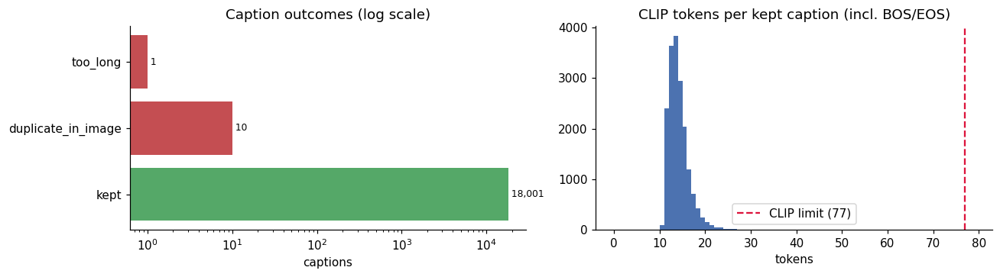

In [15]:
clean_caps = cand_caps[cand_caps.reject.isna()].copy()
keep_counts = clean_caps.groupby("image_id").size()
good_images = keep_counts[keep_counts >= CFG.min_captions_per_image].index
dropped_for_caps = set(cand_df.image_id) - set(good_images)
print(f"Images dropped for having < {CFG.min_captions_per_image} clean captions: {len(dropped_for_caps)}")

cand_df = cand_df[cand_df.image_id.isin(good_images)].reset_index(drop=True)
clean_caps = clean_caps[clean_caps.image_id.isin(good_images)].reset_index(drop=True)
log_stage(f">= {CFG.min_captions_per_image} clean captions", len(cand_df))

fig, ax = plt.subplots(1, 2, figsize=(12, 3.4))
vc = cand_caps.reject.fillna("kept").value_counts()
ax[0].barh(vc.index, vc.values, color=["#55A868" if i == "kept" else "#C44E52" for i in vc.index])
ax[0].set_xscale("log"); ax[0].set(title="Caption outcomes (log scale)", xlabel="captions")
for y, v in enumerate(vc.values):
    ax[0].text(v, y, f" {v:,}", va="center", fontsize=8)
ax[1].hist(clean_caps.n_tokens, bins=range(0, 80), color="#4C72B0")
ax[1].axvline(77, color="crimson", ls="--", label="CLIP limit (77)")
ax[1].set(title="CLIP tokens per kept caption (incl. BOS/EOS)", xlabel="tokens"); ax[1].legend()
plt.tight_layout(); savefig("03_caption_cleaning"); plt.show()

## 5. Image preprocessing (512 × 512)

Stable Diffusion v1.5 was trained at **512×512**, and its VAE downsamples by 8 → a 64×64 latent. So I:
1. apply EXIF orientation and convert to RGB,
2. resize so the **shorter side = 512** (Lanczos — the sharpest standard filter for downsampling),
3. **center-crop** to 512×512,
4. save as high-quality JPEG (q=95) under a stable name `<image_id>.jpg`.

Why resize + center-crop instead of squashing or padding: squashing distorts shapes (the model would learn stretched objects), and padding wastes pixels and teaches the model to draw borders. Center-crop is what the reference Diffusers training script uses. The trade-off is that objects near the edges can be cut off — the 2.0 aspect-ratio limit keeps this loss to at most half the long side, and the CLIP filter in Section 6 runs on the *cropped* images, so pairs whose caption no longer matches the crop tend to get filtered out.

I keep pixels as **uint8 JPEGs on disk** rather than saving tensors: conversion to `[-1, 1]` tensors (what the VAE expects) and any augmentation belong in the training `Dataset`, so they can change later without re-running this step.

In [16]:
def resize_center_crop(img: Image.Image, size: int) -> Image.Image:
    img = ImageOps.exif_transpose(img).convert("RGB")
    w, h = img.size
    scale = size / min(w, h)
    img = img.resize((max(size, round(w * scale)), max(size, round(h * scale))), Image.Resampling.LANCZOS)
    w, h = img.size
    left, top = (w - size) // 2, (h - size) // 2
    return img.crop((left, top, left + size, top + size))

def process_one(row) -> tuple:
    out = PROC_IMG / f"{row.image_id:012d}.jpg"
    if not out.exists():
        with Image.open(row.raw_path) as im:
            resize_center_crop(im, CFG.image_size).save(out, "JPEG", quality=95)
    return row.image_id, str(out)

with ThreadPoolExecutor(max_workers=8) as pool:
    done = list(tqdm(pool.map(process_one, cand_df.itertuples()), total=len(cand_df), desc="Resizing to 512"))
cand_df["proc_path"] = cand_df.image_id.map(dict(done))

# verify every output
sizes = Counter(Image.open(p).size for p in cand_df.proc_path.sample(min(200, len(cand_df)), random_state=0))
assert set(sizes) == {(CFG.image_size, CFG.image_size)}, sizes
print(f"All checked images are {CFG.image_size}x{CFG.image_size}. "
      f"Processed folder: {sum(p.stat().st_size for p in PROC_IMG.glob('*.jpg')) / 1e6:.0f} MB")

Resizing to 512:   0%|          | 0/3600 [00:00<?, ?it/s]

All checked images are 512x512. Processed folder: 423 MB


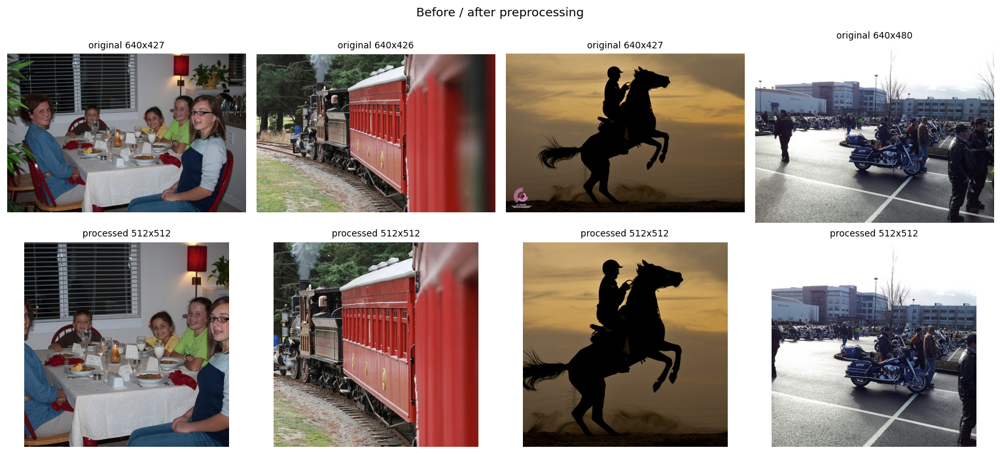

In [17]:
demo = cand_df.sample(4, random_state=1)
fig, ax = plt.subplots(2, 4, figsize=(14, 6.4))
for k, row in enumerate(demo.itertuples()):
    raw = Image.open(row.raw_path)
    ax[0, k].imshow(raw); ax[0, k].set_title(f"original {raw.size[0]}x{raw.size[1]}", fontsize=9)
    ax[1, k].imshow(Image.open(row.proc_path)); ax[1, k].set_title("processed 512x512", fontsize=9)
    ax[0, k].axis("off"); ax[1, k].axis("off")
plt.suptitle("Before / after preprocessing"); plt.tight_layout(); savefig("04_preprocessing"); plt.show()

## 6. CLIP-based alignment filtering

Rule-based cleaning catches broken text, but not captions that are well-formed and **wrong for the image** (or right for the full image but not for the center crop). For a generative model, misaligned pairs are the most harmful kind of noise, since the model learns to associate words with the wrong visuals.

I score every (image, caption) pair with **CLIP ViT-L/14**, the same family of model Stable Diffusion's text encoder comes from. The CLIP score is the cosine similarity between the L2-normalized image and text embeddings (the same idea LAION used to filter web-scale data). Then:

1. **Drop individual captions** in the worst 1% of all caption scores.
2. For each image, choose the **primary caption** = the caption with the highest CLIP score. This becomes the image's single "pair" for training; the other captions are kept as extra positives (useful later as caption augmentation and right now for retrieval evaluation).
3. **Drop whole images** whose *mean* caption score is in the worst 5%. A low mean means all five annotators struggled to describe the cropped image, which usually means a cluttered or ambiguous image.

Note I compute embeddings directly through `vision_model → visual_projection` and `text_model → text_projection` rather than through `get_*_features` helpers, so the code doesn't depend on helper return types that changed between `transformers` versions. A sanity check compares my path to the model's own forward pass.

In [18]:
clip_model = CLIPModel.from_pretrained(CFG.clip_model_id).to(DEVICE).eval()
clip_processor = CLIPProcessor.from_pretrained(CFG.clip_model_id)
tokenizer = clip_processor.tokenizer
n_params = sum(p.numel() for p in clip_model.parameters()) / 1e6
print(f"Loaded {CFG.clip_model_id}: {n_params:.0f}M params | text width {clip_model.config.text_config.hidden_size} "
      f"| projection dim {clip_model.config.projection_dim} | context {tokenizer.model_max_length}")

@torch.no_grad()
def embed_pil_images(imgs) -> torch.Tensor:
    px = clip_processor.image_processor(images=[im.convert("RGB") for im in imgs], return_tensors="pt")["pixel_values"]
    feats = clip_model.visual_projection(clip_model.vision_model(pixel_values=px.to(DEVICE)).pooler_output)
    return F.normalize(feats, dim=-1).float().cpu()

def clip_image_embeds(paths, batch_size: int = CFG.batch_size) -> torch.Tensor:
    out = []
    for i in tqdm(range(0, len(paths), batch_size), desc="CLIP image embeddings"):
        out.append(embed_pil_images([Image.open(p) for p in paths[i:i + batch_size]]))
    return torch.cat(out)

@torch.no_grad()
def clip_text_embeds(texts, batch_size: int = 256) -> torch.Tensor:
    out = []
    for i in range(0, len(texts), batch_size):
        tok = tokenizer(texts[i:i + batch_size], padding="max_length", max_length=CFG.max_tokens,
                        truncation=True, return_tensors="pt")
        feats = clip_model.text_projection(clip_model.text_model(input_ids=tok.input_ids.to(DEVICE)).pooler_output)
        out.append(F.normalize(feats, dim=-1).float().cpu())
    return torch.cat(out)

# sanity check: my embedding path == CLIPModel's own forward pass
with torch.no_grad():
    s_paths, s_texts = cand_df.proc_path[:2].tolist(), clean_caps.clean[:2].tolist()
    ref = clip_model(**clip_processor(text=s_texts, images=[Image.open(p) for p in s_paths],
                                      return_tensors="pt", padding=True).to(DEVICE))
    assert torch.allclose(ref.image_embeds.float().cpu(), clip_image_embeds(s_paths), atol=1e-4)
    assert torch.allclose(ref.text_embeds.float().cpu(), clip_text_embeds(s_texts), atol=1e-4)
print("Embedding path matches CLIPModel.forward(): OK")

config.json:   0%|          | 0.00/4.52k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.71GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/590 [00:00<?, ?it/s]

preprocessor_config.json:   0%|          | 0.00/316 [00:00<?, ?B/s]

Loaded openai/clip-vit-large-patch14: 428M params | text width 768 | projection dim 768 | context 77


CLIP image embeddings:   0%|          | 0/1 [00:00<?, ?it/s]

Embedding path matches CLIPModel.forward(): OK


In [19]:
t0 = time.time()
cand_df = cand_df.reset_index(drop=True)
IMG_EMB = clip_image_embeds(cand_df.proc_path.tolist())                 # [N_img, 768], unit norm
img_row = {iid: k for k, iid in enumerate(cand_df.image_id)}

TXT_EMB = clip_text_embeds(clean_caps.clean.tolist())                   # [N_cap, 768], unit norm
clean_caps["clip_score"] = (TXT_EMB * IMG_EMB[clean_caps.image_id.map(img_row).values]).sum(-1).numpy()
print(f"Scored {len(clean_caps):,} pairs in {time.time() - t0:.0f}s")
print(clean_caps.clip_score.describe().round(3).to_string())

# for comparison: what does a *mismatched* pair score? (each caption vs a random other image)
perm = np.random.default_rng(CFG.seed).permutation(len(cand_df))
rand_img = IMG_EMB[perm[clean_caps.image_id.map(img_row).values]]
random_scores = (TXT_EMB * rand_img).sum(-1).numpy()
print(f"\nMatched pairs mean {clean_caps.clip_score.mean():.3f}  vs  random pairs mean {random_scores.mean():.3f}")

CLIP image embeddings:   0%|          | 0/57 [00:00<?, ?it/s]

Scored 18,001 pairs in 258s
count    18001.000
mean         0.255
std          0.038
min          0.086
25%          0.230
50%          0.255
75%          0.280
max          0.439

Matched pairs mean 0.255  vs  random pairs mean 0.086


Caption threshold (p1) = 0.160 -> dropping 180 captions
Image threshold (p5 of mean score) = 0.210 -> dropping 183 images


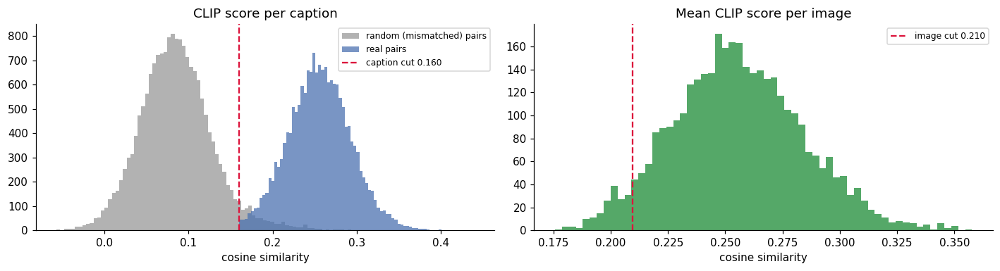

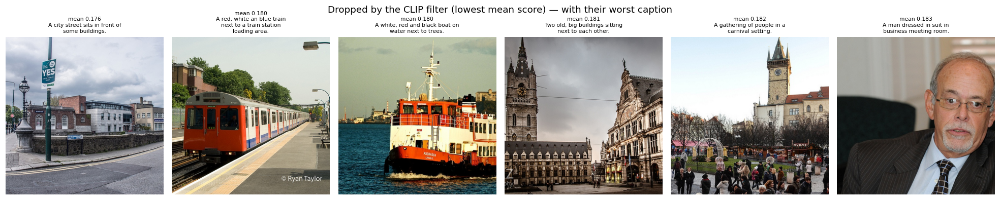

In [20]:
# (1) drop worst-aligned individual captions
cap_thr = np.percentile(clean_caps.clip_score, CFG.clip_caption_drop_pct)
low_caps = clean_caps.clip_score < cap_thr
print(f"Caption threshold (p{CFG.clip_caption_drop_pct:g}) = {cap_thr:.3f} -> dropping {low_caps.sum()} captions")
dropped_low_caps = clean_caps[low_caps]
clean_caps = clean_caps[~low_caps].reset_index(drop=True)

# (3) drop worst-aligned images by mean caption score
img_stats = clean_caps.groupby("image_id").clip_score.agg(["mean", "max", "count"])
img_thr = np.percentile(img_stats["mean"], CFG.clip_image_drop_pct)
bad_imgs = img_stats.index[(img_stats["mean"] < img_thr) | (img_stats["count"] < CFG.min_captions_per_image)]
print(f"Image threshold (p{CFG.clip_image_drop_pct:g} of mean score) = {img_thr:.3f} -> dropping {len(bad_imgs)} images")

fig, ax = plt.subplots(1, 2, figsize=(13, 3.6))
ax[0].hist(random_scores, bins=80, alpha=.6, color="gray", label="random (mismatched) pairs")
ax[0].hist(clean_caps.clip_score, bins=80, alpha=.75, color="#4C72B0", label="real pairs")
ax[0].axvline(cap_thr, color="crimson", ls="--", label=f"caption cut {cap_thr:.3f}")
ax[0].set(title="CLIP score per caption", xlabel="cosine similarity"); ax[0].legend(fontsize=8)
ax[1].hist(img_stats["mean"], bins=60, color="#55A868")
ax[1].axvline(img_thr, color="crimson", ls="--", label=f"image cut {img_thr:.3f}")
ax[1].set(title="Mean CLIP score per image", xlabel="cosine similarity"); ax[1].legend(fontsize=8)
plt.tight_layout(); savefig("05_clip_scores"); plt.show()

worst = img_stats.loc[bad_imgs].sort_values("mean").head(6)
fig, ax = plt.subplots(1, len(worst), figsize=(3 * len(worst), 3.8))
for a, (iid, r) in zip(np.atleast_1d(ax), worst.iterrows()):
    cap = clean_caps[clean_caps.image_id == iid].sort_values("clip_score").clean.iloc[0]
    a.imshow(Image.open(cand_df.proc_path[img_row[iid]])); a.axis("off")
    a.set_title(f"mean {r['mean']:.3f}\n" + "\n".join(textwrap.wrap(cap, 30)[:3]), fontsize=7)
plt.suptitle("Dropped by the CLIP filter (lowest mean score) — with their worst caption"); plt.tight_layout()
savefig("06_clip_dropped"); plt.show()

In [21]:
# (2) choose the primary caption (highest CLIP score) for each surviving image
clean_caps = clean_caps[~clean_caps.image_id.isin(bad_imgs)].reset_index(drop=True)
cand_df = cand_df[~cand_df.image_id.isin(bad_imgs)].reset_index(drop=True)
log_stage("after CLIP alignment filter", len(cand_df))

if len(cand_df) > CFG.n_target_images:
    cand_df = cand_df.sample(n=CFG.n_target_images, random_state=CFG.seed).reset_index(drop=True)
elif len(cand_df) < CFG.n_target_images:
    print(f"Only {len(cand_df)} images survived (target {CFG.n_target_images}); increase n_candidates if needed.")
clean_caps = clean_caps[clean_caps.image_id.isin(cand_df.image_id)].reset_index(drop=True)

primary_idx = clean_caps.groupby("image_id").clip_score.idxmax()
clean_caps["is_primary"] = False
clean_caps.loc[primary_idx.values, "is_primary"] = True
assert clean_caps.groupby("image_id").is_primary.sum().eq(1).all()

prim = clean_caps[clean_caps.is_primary].set_index("image_id")
cand_df["text"] = cand_df.image_id.map(prim.clean)
cand_df["clip_score"] = cand_df.image_id.map(prim.clip_score)
log_stage("final dataset", len(cand_df))
print(f"Final: {len(cand_df):,} images, {len(clean_caps):,} captions "
      f"({len(clean_caps) / len(cand_df):.2f} per image), primary-pair CLIP score mean {cand_df.clip_score.mean():.3f}")

[funnel] after CLIP alignment filter                      3,417
[funnel] final dataset                                    3,000
Final: 3,000 images, 14,899 captions (4.97 per image), primary-pair CLIP score mean 0.287


## 7. Splits & export

**Splits:** 80 / 10 / 10 train / val / test, split **by image**, so all captions of an image land in the same split and nothing leaks into evaluation.

**Export format** — chosen so Milestone 2 can load it with zero glue code:

| File | Contents |
|---|---|
| `processed/images/<id>.jpg` | 512×512 RGB images |
| `processed/metadata.jsonl` | one line per image: `file_name`, `text` (primary caption), `split`, `image_id`, `clip_score`, `all_captions`. This is the Hugging Face **ImageFolder** layout, so `load_dataset("imagefolder", data_dir="processed")` works directly, and it's what the Diffusers `train_text_to_image.py` script expects. |
| `processed/pairs_primary.csv` | the same image–caption pairs as a flat table |
| `processed/captions_all.csv` | every kept caption with raw text, cleaned text, CLIP score, primary flag, split |

In [22]:
rng = np.random.default_rng(CFG.seed)
order = rng.permutation(len(cand_df))
n_tr = int(CFG.split_fracs[0] * len(cand_df))
n_va = int(CFG.split_fracs[1] * len(cand_df))
split = np.empty(len(cand_df), dtype=object)
split[order[:n_tr]] = "train"
split[order[n_tr:n_tr + n_va]] = "val"
split[order[n_tr + n_va:]] = "test"
cand_df["split"] = split
clean_caps["split"] = clean_caps.image_id.map(cand_df.set_index("image_id").split)

# no image may appear in two splits
assert cand_df.groupby("image_id").split.nunique().max() == 1
assert clean_caps.groupby("image_id").split.nunique().max() == 1
print(cand_df.split.value_counts().reindex(["train", "val", "test"]).to_string())

# remove processed images that didn't make the final cut, so the folder == the dataset
final_files = {Path(p).name for p in cand_df.proc_path}
removed = 0
for p in PROC_IMG.glob("*.jpg"):
    if p.name not in final_files:
        p.unlink(); removed += 1
print(f"Removed {removed} processed images that were filtered out")

all_caps_by_img = clean_caps.groupby("image_id").clean.apply(list)
with open(PROC_DIR / "metadata.jsonl", "w") as f:
    for r in cand_df.itertuples():
        f.write(json.dumps({
            "file_name": f"images/{Path(r.proc_path).name}",
            "text": r.text,
            "split": r.split,
            "image_id": int(r.image_id),
            "clip_score": round(float(r.clip_score), 4),
            "all_captions": all_caps_by_img[r.image_id],
        }) + "\n")

cand_df[["image_id", "split", "text", "clip_score", "proc_path", "file_name", "coco_url"]].rename(
    columns={"file_name": "coco_file_name"}).to_csv(PROC_DIR / "pairs_primary.csv", index=False)
clean_caps[["caption_id", "image_id", "split", "caption", "clean", "n_tokens", "clip_score", "is_primary"]].rename(
    columns={"caption": "caption_raw", "clean": "caption_clean"}).to_csv(PROC_DIR / "captions_all.csv", index=False)

# round-trip check
meta = pd.read_json(PROC_DIR / "metadata.jsonl", lines=True)
assert len(meta) == len(cand_df) and meta.file_name.map(lambda f: (PROC_DIR / f).exists()).all()
print(f"Exported metadata.jsonl ({len(meta)} rows), pairs_primary.csv, captions_all.csv — all files exist")
meta.head(3)

split
train    2400
val       300
test      300
Removed 600 processed images that were filtered out
Exported metadata.jsonl (3000 rows), pairs_primary.csv, captions_all.csv — all files exist


,file_name,text,split,image_id,clip_score,all_captions
0,images/000000575873.jpg,A bloodied zombie wearing a hat in a crowd of zombies.,train,575873,0.3339,"[A man with blood pouring out of his mouth and nose., A bloodied zombie wearing a hat in a crowd of zombies., A man ..."
1,images/000000393266.jpg,A car is driving through a tunnel in a city street.,train,393266,0.2956,"[A car driving through a tunnel under buildings., Car passing through a very small tunnel in a city street., A car d..."
2,images/000000185991.jpg,Women lined up with luggage beside a bus.,train,185991,0.2621,"[Women lined up with luggage beside a bus., Weary travelers get off a bus and collect their luggage from a table., A..."


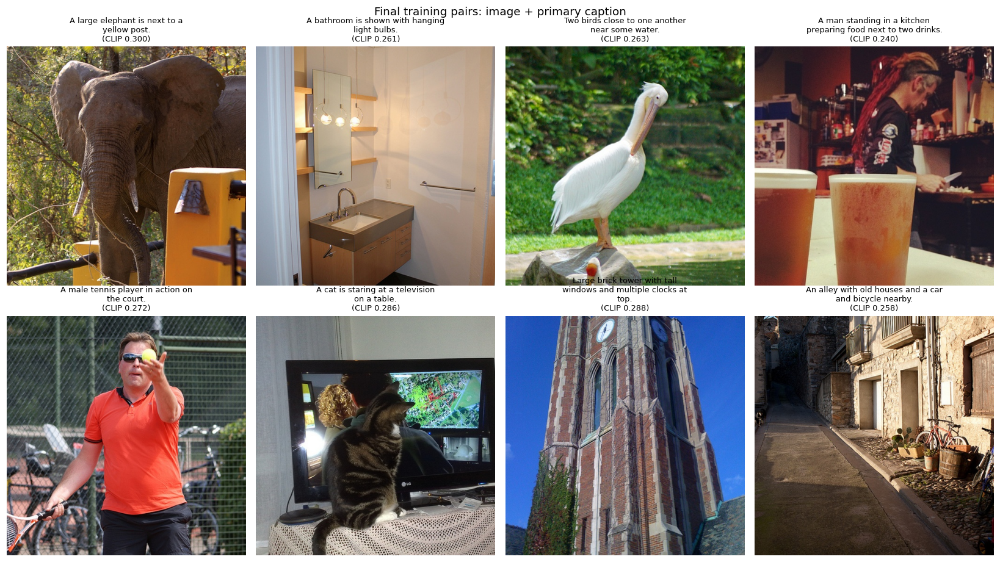

In [23]:
show = cand_df[cand_df.split == "train"].sample(8, random_state=CFG.seed)
fig, ax = plt.subplots(2, 4, figsize=(15, 8.6))
for a, r in zip(ax.flat, show.itertuples()):
    a.imshow(Image.open(r.proc_path)); a.axis("off")
    a.set_title("\n".join(textwrap.wrap(r.text, 34)) + f"\n(CLIP {r.clip_score:.3f})", fontsize=8.5)
plt.suptitle("Final training pairs: image + primary caption"); plt.tight_layout(); savefig("07_final_pairs"); plt.show()

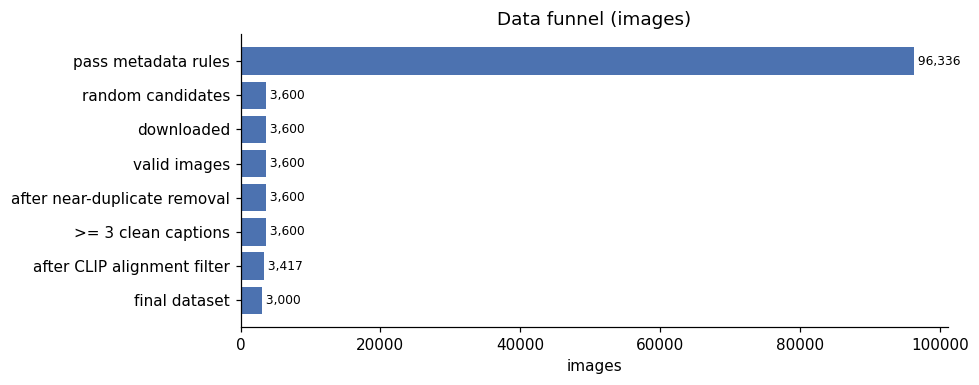

,stage,images
0,COCO train2017 images,118287
1,pass metadata rules,96336
2,random candidates,3600
3,downloaded,3600
4,valid images,3600
5,after near-duplicate removal,3600
6,>= 3 clean captions,3600
7,after CLIP alignment filter,3417
8,final dataset,3000


{
  "images": 3000,
  "captions": 14899,
  "captions_per_image": 4.97,
  "split_counts": {
    "train": 2400,
    "test": 300,
    "val": 300
  },
  "words_per_primary_caption_mean": 10.9,
  "tokens_per_caption_max": 45,
  "primary_clip_score_mean": 0.2867,
  "primary_clip_score_min": 0.2153,
  "image_resolution": "512x512"
}


In [24]:
funnel_df = pd.DataFrame(FUNNEL, columns=["stage", "images"])
fig, ax = plt.subplots(figsize=(9, 3.6))
sub = funnel_df.iloc[1:]                  # skip the full-COCO bar so the rest is readable
ax.barh(sub.stage[::-1], sub.images[::-1], color="#4C72B0")
for y, v in enumerate(sub.images[::-1]):
    ax.text(v, y, f" {v:,}", va="center", fontsize=8)
ax.set(title="Data funnel (images)", xlabel="images"); plt.tight_layout(); savefig("08_funnel"); plt.show()

DATASET_STATS = {
    "images": len(cand_df),
    "captions": len(clean_caps),
    "captions_per_image": round(len(clean_caps) / len(cand_df), 2),
    "split_counts": cand_df.split.value_counts().to_dict(),
    "words_per_primary_caption_mean": round(cand_df.text.str.split().str.len().mean(), 2),
    "tokens_per_caption_max": int(clean_caps.n_tokens.max()),
    "primary_clip_score_mean": round(float(cand_df.clip_score.mean()), 4),
    "primary_clip_score_min": round(float(cand_df.clip_score.min()), 4),
    "image_resolution": f"{CFG.image_size}x{CFG.image_size}",
}
display(funnel_df)
print(json.dumps(DATASET_STATS, indent=2))

## 8. Text → embedding pipeline

This is the core deliverable of the milestone: a single, reusable component that turns any caption or prompt into the tensors a text-to-image model needs.

```
raw text ──► clean_caption()            same normalization as the training captions
         ──► CLIP BPE tokenizer          <|startoftext|> … <|endoftext|>, pad/truncate to 77
         ──► CLIP ViT-L/14 text encoder  12 transformer layers, width 768, causal attention
                │
                ├─► last_hidden_state  [B, 77, 768]   ← CONDITIONING: the SD U-Net cross-attends to all 77 tokens
                │
                └─► EOS-token output → text_projection → L2-normalize  [B, 768]
                                                          ← POOLED: CLIP joint image–text space (retrieval, scoring)
```

Design decisions:
* **Why this exact encoder:** Stable Diffusion v1.x was trained with the frozen text encoder of `openai/clip-vit-large-patch14`. Using the same model means the embeddings I compute and cache now can be fed directly to the SD U-Net. Section 9 checks this numerically against the encoder inside the SD repo.
* **Two outputs, two jobs:** the per-token hidden states carry word-level detail for cross-attention ("a *red* cube *on* a *blue* sphere"); the pooled embedding is a single vector that lives in the same space as CLIP image embeddings, which is what I use for alignment checks, retrieval and quality evaluation.
* **No attention mask on the encoder input**, deliberately: SD's own `encode_prompt` doesn't pass one for v1.5, and CLIP's causal mask already prevents real tokens from attending to the padding after them. Matching SD exactly matters more than a theoretical cleanliness.
* **The unconditional embedding** (the empty prompt `""`) is computed once and saved; classifier-free guidance needs it at both training time (caption dropout) and sampling time.
* **Caching:** embeddings are computed once and saved, so later training can skip the text encoder entirely (saves ~0.5 GB of VRAM and time per step).

In [25]:
class TextEmbeddingPipeline:
    # Text -> (per-token conditioning, pooled CLIP embedding), compatible with Stable Diffusion v1.x.

    def __init__(self, model: CLIPModel, tokenizer: CLIPTokenizer, device: torch.device,
                 max_length: int = 77, clean: bool = True):
        self.model = model.eval()
        self.tokenizer = tokenizer
        self.device = device
        self.max_length = max_length
        self.clean = clean
        self.hidden_size = model.config.text_config.hidden_size
        self.proj_dim = model.config.projection_dim

    def preprocess(self, texts):
        if isinstance(texts, str):
            texts = [texts]
        return [clean_caption(t) if (self.clean and t.strip()) else t for t in texts]

    def tokenize(self, texts):
        return self.tokenizer(texts, padding="max_length", max_length=self.max_length,
                              truncation=True, return_tensors="pt")

    @torch.no_grad()
    def encode(self, texts, normalize: bool = True) -> dict:
        texts = self.preprocess(texts)
        tok = self.tokenize(texts)
        ids = tok.input_ids.to(self.device)
        out = self.model.text_model(input_ids=ids)                    # matches SD: no attention_mask
        hidden = out.last_hidden_state                                 # [B, 77, 768] (final layer norm applied)
        pooled = self.model.text_projection(out.pooler_output)         # [B, 768]
        if normalize:
            pooled = F.normalize(pooled, dim=-1)
        return {"texts": texts, "input_ids": tok.input_ids, "attention_mask": tok.attention_mask,
                "hidden_states": hidden, "pooled": pooled}

    def encode_corpus(self, texts, batch_size: int = 128, keep_hidden: bool = False,
                      hidden_dtype=torch.float16, desc: str = "Encoding"):
        pooled, hidden = [], []
        for i in tqdm(range(0, len(texts), batch_size), desc=desc):
            out = self.encode(texts[i:i + batch_size])
            pooled.append(out["pooled"].float().cpu())
            if keep_hidden:
                hidden.append(out["hidden_states"].to(hidden_dtype).cpu())
        return torch.cat(pooled), (torch.cat(hidden) if keep_hidden else None)

    def __call__(self, texts):
        return self.encode(texts)

text_pipe = TextEmbeddingPipeline(clip_model, tokenizer, DEVICE, max_length=CFG.max_tokens)
demo = text_pipe(["a dog catching a frisbee in a park", "  A bowl of fruit on a table ."])
for k in ["hidden_states", "pooled", "input_ids"]:
    print(f"{k:>14}: {tuple(demo[k].shape)}  {demo[k].dtype}")
print("cleaned texts:", demo["texts"])

 hidden_states: (2, 77, 768)  torch.float32
        pooled: (2, 768)  torch.float32
     input_ids: (2, 77)  torch.int64
cleaned texts: ['A dog catching a frisbee in a park.', 'A bowl of fruit on a table.']


### Tokenization, step by step
Looking at the tokens explains several things: CLIP's BPE tokenizer lowercases text, splits words into sub-word pieces (`</w>` marks the end of a word), wraps everything in start/end tokens, and pads to 77. In the openai tokenizer the padding token *is* `<|endoftext|>`, which is why the pooled embedding is taken from the **first** end token.

In [26]:
example = cand_df.text.iloc[0]
tok = text_pipe.tokenize(text_pipe.preprocess(example))
ids = tok.input_ids[0]
n_real = int(tok.attention_mask[0].sum())
tok_table = pd.DataFrame({
    "position": range(n_real + 2),
    "token": tokenizer.convert_ids_to_tokens(ids[:n_real + 2]),
    "id": ids[:n_real + 2].tolist(),
    "attention_mask": tok.attention_mask[0][:n_real + 2].tolist(),
})
print(f"Caption: {example!r}")
print(f"{n_real} real tokens (incl. BOS/EOS) + {CFG.max_tokens - n_real} padding = {CFG.max_tokens}")
print(f"BOS id {tokenizer.bos_token_id}, EOS id {tokenizer.eos_token_id}, PAD id {tokenizer.pad_token_id}")
display(tok_table.T)

Caption: 'A bloodied zombie wearing a hat in a crowd of zombies.'
15 real tokens (incl. BOS/EOS) + 62 padding = 77
BOS id 49406, EOS id 49407, PAD id 49407


,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16
position,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16
token,<|startoftext|>,a</w>,bloo,died</w>,zombie</w>,wearing</w>,a</w>,hat</w>,in</w>,a</w>,crowd</w>,of</w>,zombies</w>,.</w>,<|endoftext|>,<|endoftext|>,<|endoftext|>
id,49406,320,2373,3622,11819,3309,320,3801,530,320,4570,539,16517,269,49407,49407,49407
attention_mask,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,0


In [27]:
lens = clean_caps.n_tokens.values
print(f"Tokens per caption: mean {lens.mean():.1f}, p95 {np.percentile(lens, 95):.0f}, max {lens.max()} (limit {CFG.max_tokens})")
print(f"Captions that would be truncated: {(lens > CFG.max_tokens).sum()}")
print(f"Average padding fraction of the 77 slots: {1 - lens.mean() / CFG.max_tokens:.1%}")
vocab = Counter(t for ids_ in tokenizer(clean_caps.clean.tolist())["input_ids"] for t in ids_[1:-1])
print(f"Distinct BPE tokens used by the corpus: {len(vocab):,} of {tokenizer.vocab_size:,}")
print("Most frequent tokens:", [tokenizer.convert_ids_to_tokens(i) for i, _ in vocab.most_common(15)])

Tokens per caption: mean 13.7, p95 18, max 45 (limit 77)
Captions that would be truncated: 0
Average padding fraction of the 77 slots: 82.1%
Distinct BPE tokens used by the corpus: 5,770 of 49,408
Most frequent tokens: ['a</w>', '.</w>', 'on</w>', 'of</w>', 'the</w>', 'in</w>', 'with</w>', 'and</w>', 'is</w>', 'man</w>', 'to</w>', 'sitting</w>', 'an</w>', 'two</w>', 'standing</w>']


### Encoding and caching the whole dataset
* **Pooled embeddings for every caption** (~15k × 768, small) — used for retrieval and analysis.
* **Full 77×768 conditioning for each image's primary caption**, stored in **fp16** to halve disk use (~355 MB for 3k images). fp16 is what the U-Net runs in on a GPU anyway.
* **Unconditional (`""`) embedding**, needed for classifier-free guidance.
* **CLIP image embeddings** from Section 6, aligned to the same image order.

In [28]:
t0 = time.time()
cand_df = cand_df.reset_index(drop=True)
clean_caps = clean_caps.reset_index(drop=True)

pooled_all, _ = text_pipe.encode_corpus(clean_caps.clean.tolist(), batch_size=256, desc="Pooled (all captions)")
pooled_prim, hidden_prim = text_pipe.encode_corpus(cand_df.text.tolist(), batch_size=64, keep_hidden=True,
                                                   desc="Conditioning (primary captions)")
uncond = text_pipe.encode([""])
uncond_hidden = uncond["hidden_states"].float().cpu()                 # [1, 77, 768]

# image embeddings re-ordered to match cand_df
img_emb_final = IMG_EMB[[img_row[i] for i in cand_df.image_id]]

torch.save({"embeds": pooled_all, "caption_ids": torch.tensor(clean_caps.caption_id.values),
            "image_ids": torch.tensor(clean_caps.image_id.values), "texts": clean_caps.clean.tolist(),
            "model": CFG.clip_model_id}, EMB_DIR / "text_pooled_all_captions.pt")
torch.save({"hidden_states": hidden_prim, "pooled": pooled_prim,
            "image_ids": torch.tensor(cand_df.image_id.values), "texts": cand_df.text.tolist(),
            "splits": cand_df.split.tolist(), "model": CFG.clip_model_id}, EMB_DIR / "text_conditioning_primary.pt")
torch.save({"hidden_states": uncond_hidden, "text": ""}, EMB_DIR / "uncond_embedding.pt")
torch.save({"embeds": img_emb_final, "image_ids": torch.tensor(cand_df.image_id.values)}, EMB_DIR / "image_embeds.pt")

print(f"Encoded in {time.time() - t0:.0f}s")
print(f"pooled_all {tuple(pooled_all.shape)} | hidden_prim {tuple(hidden_prim.shape)} {hidden_prim.dtype} "
      f"| uncond {tuple(uncond_hidden.shape)} | image {tuple(img_emb_final.shape)}")
for p in sorted(EMB_DIR.glob("*.pt")):
    print(f"  {p.name:<36} {p.stat().st_size / 1e6:8.1f} MB")

Pooled (all captions):   0%|          | 0/59 [00:00<?, ?it/s]

Conditioning (primary captions):   0%|          | 0/47 [00:00<?, ?it/s]

Encoded in 86s
pooled_all (14899, 768) | hidden_prim (3000, 77, 768) torch.float16 | uncond (1, 77, 768) | image (3000, 768)
  image_embeds.pt                           9.2 MB
  text_conditioning_primary.pt            364.3 MB
  text_pooled_all_captions.pt              46.9 MB
  uncond_embedding.pt                       0.2 MB


## 9. Validating the pipeline

A pipeline that returns tensors of the right shape can still be wrong in subtle ways, for example by using a different text encoder than the diffusion model, depending on batch composition, or silently truncating. Each check below targets a specific way it could fail.

In [29]:
CHECKS = []
def check(name: str, passed: bool, detail: str = "") -> None:
    CHECKS.append({"check": name, "passed": bool(passed), "detail": detail})

sample = cand_df.text.sample(16, random_state=CFG.seed).tolist()
o1 = text_pipe.encode(sample)
H, P = o1["hidden_states"], o1["pooled"]

check("hidden_states shape [B,77,768]", tuple(H.shape) == (16, CFG.max_tokens, text_pipe.hidden_size), str(tuple(H.shape)))
check("pooled shape [B,768]", tuple(P.shape) == (16, text_pipe.proj_dim), str(tuple(P.shape)))
check("no NaN / Inf", bool(torch.isfinite(H).all() and torch.isfinite(P).all()))
norms = P.norm(dim=-1)
check("pooled vectors are unit norm", bool(torch.allclose(norms, torch.ones_like(norms), atol=1e-4)),
      f"norm range [{norms.min():.5f}, {norms.max():.5f}]")

o2 = text_pipe.encode(sample)
check("deterministic (same input -> same output)", bool(torch.equal(o2["hidden_states"], H)))

single = torch.cat([text_pipe.encode([s])["hidden_states"] for s in sample[:4]])
d_batch = (single - H[:4]).abs().max().item()
check("batch-invariant (alone vs in a batch)", d_batch < 1e-3, f"max |diff| = {d_batch:.2e}")

with torch.no_grad():
    ref = clip_model(**clip_processor(text=sample, images=[Image.new("RGB", (224, 224))] * len(sample),
                                      return_tensors="pt", padding=True).to(DEVICE)).text_embeds
cos_ref = F.cosine_similarity(ref, P, dim=-1).min().item()
check("pooled == CLIPModel.forward().text_embeds", cos_ref > 0.9999, f"min cosine = {cos_ref:.6f}")

idem = all(clean_caption(t) == t for t in clean_caps.clean)
check("caption cleaning is idempotent on the corpus", idem)
check("no caption exceeds 77 tokens", int(clean_caps.n_tokens.max()) <= CFG.max_tokens, f"max = {clean_caps.n_tokens.max()}")

diff_txt = F.cosine_similarity(P[0:1], P[1:2]).item()
check("different captions -> different embeddings", diff_txt < 0.99, f"cosine(caption0, caption1) = {diff_txt:.3f}")

### Parity with Stable Diffusion's own text encoder
The strongest check: load the tokenizer and text encoder **from the Stable Diffusion v1.5 repository itself** and confirm my pipeline produces the same token ids and the same 77×768 conditioning tensor. If this passes, my cached embeddings can be fed directly into the SD U-Net.

In [30]:
sd_tokenizer = CLIPTokenizer.from_pretrained(CFG.sd_model_id, subfolder="tokenizer")
sd_text_encoder = CLIPTextModel.from_pretrained(CFG.sd_model_id, subfolder="text_encoder").to(DEVICE).eval()

with torch.no_grad():
    sd_ids = sd_tokenizer(sample, padding="max_length", max_length=sd_tokenizer.model_max_length,
                          truncation=True, return_tensors="pt").input_ids
    sd_hidden = sd_text_encoder(sd_ids.to(DEVICE))[0]             # exactly what SD's encode_prompt does

ids_equal = torch.equal(sd_ids, o1["input_ids"])
max_diff = (sd_hidden - H).abs().max().item()
cos_min = F.cosine_similarity(sd_hidden.flatten(1), H.flatten(1), dim=-1).min().item()
check("token ids identical to SD tokenizer", ids_equal)
check("conditioning matches SD text encoder", cos_min > 0.9999, f"max |diff| = {max_diff:.2e}, min cosine = {cos_min:.6f}")

print(f"SD tokenizer max length: {sd_tokenizer.model_max_length} | SD text encoder hidden size: {sd_text_encoder.config.hidden_size}")
del sd_text_encoder
if DEVICE.type == "cuda":
    torch.cuda.empty_cache()

checks_df = pd.DataFrame(CHECKS)
display(checks_df)
assert checks_df.passed.all(), "Some pipeline checks failed — see table above"
print(f"All {len(checks_df)} checks passed")

tokenizer_config.json:   0%|          | 0.00/806 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/1.06M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/525k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/472 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/617 [00:00<?, ?B/s]

text_encoder/model.safetensors: reconstructing file:   0%|          |  0.00B /  492MB            

text_encoder/model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

SD tokenizer max length: 77 | SD text encoder hidden size: 768


,check,passed,detail
0,"hidden_states shape [B,77,768]",True,"(16, 77, 768)"
1,"pooled shape [B,768]",True,"(16, 768)"
2,no NaN / Inf,True,
3,pooled vectors are unit norm,True,"norm range [1.00000, 1.00000]"
4,deterministic (same input -> same output),True,
5,batch-invariant (alone vs in a batch),True,max |diff| = 8.11e-06
6,pooled == CLIPModel.forward().text_embeds,True,min cosine = 1.000000
7,caption cleaning is idempotent on the corpus,True,
8,no caption exceeds 77 tokens,True,max = 45
9,different captions -> different embeddings,True,"cosine(caption0, caption1) = 0.483"


All 12 checks passed


## 10. Do the embeddings mean anything?

Passing the checks shows the pipeline is *correct*; this section shows the embeddings are *meaningful* on my data. Three views:

1. **Similarity structure:** captions of the same image should be closer to each other than to captions of other images.
2. **Cross-modal retrieval** on the held-out test split: given a caption, can the CLIP space find its image (and vice versa)? Recall@K is a standard, interpretable metric for this.
3. **t-SNE map + free-text search:** do semantic groups (animals, food, vehicles, …) form neighbourhoods, and do arbitrary prompts retrieve sensible images?

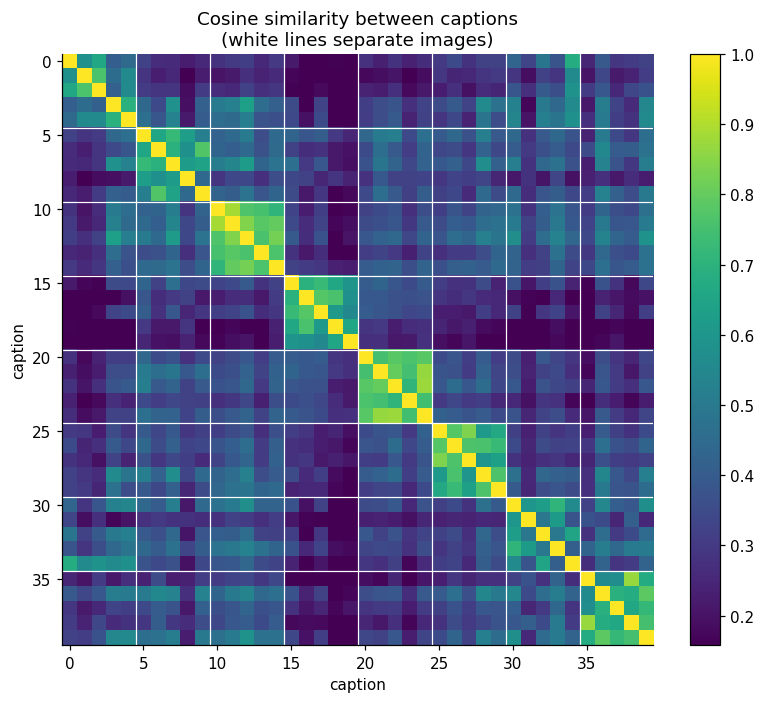

Mean similarity — same image: 0.672 | different images: 0.328


In [31]:
pick = cand_df[cand_df.split == "test"].sample(8, random_state=CFG.seed).image_id.tolist()
sub = clean_caps[clean_caps.image_id.isin(pick)].copy()
sub["order"] = sub.image_id.map({iid: k for k, iid in enumerate(pick)})
sub = sub.sort_values(["order", "caption_id"])
E = pooled_all[sub.index.values]
S = (E @ E.T).numpy()

fig, ax = plt.subplots(figsize=(7.5, 6.5))
im = ax.imshow(S, cmap="viridis", vmin=np.percentile(S, 5), vmax=1)
bounds = np.cumsum(sub.groupby("order").size().values)[:-1] - 0.5
for b in bounds:
    ax.axhline(b, color="white", lw=0.8); ax.axvline(b, color="white", lw=0.8)
ax.set(title="Cosine similarity between captions\n(white lines separate images)", xlabel="caption", ylabel="caption")
plt.colorbar(im, fraction=0.046); plt.tight_layout(); savefig("09_caption_similarity"); plt.show()

same = (sub.image_id.values[:, None] == sub.image_id.values[None, :]) & ~np.eye(len(sub), dtype=bool)
diff = sub.image_id.values[:, None] != sub.image_id.values[None, :]
print(f"Mean similarity — same image: {S[same].mean():.3f} | different images: {S[diff].mean():.3f}")

In [32]:
def recall_at_k(sim: torch.Tensor, gt_mask: torch.Tensor, ks=(1, 5, 10)) -> dict:
    # sim: [queries, candidates]; gt_mask: same shape, True where the candidate is a correct match
    ranks = sim.argsort(dim=1, descending=True)
    hits = torch.gather(gt_mask, 1, ranks)
    return {f"R@{k}": round(hits[:, :k].any(dim=1).float().mean().item() * 100, 2) for k in ks}

test_imgs = cand_df[cand_df.split == "test"].reset_index(drop=True)
test_caps = clean_caps[clean_caps.split == "test"]
I = img_emb_final[cand_df.index[cand_df.split == "test"].values]
T = pooled_all[test_caps.index.values]
pos = torch.tensor(test_caps.image_id.values)[:, None] == torch.tensor(test_imgs.image_id.values)[None, :]

t2i = recall_at_k(T @ I.T, pos)                       # caption -> image
i2t = recall_at_k(I @ T.T, pos.T.contiguous())        # image -> any of its captions
n_i, caps_per = len(test_imgs), len(test_caps) / len(test_imgs)
chance_t2i = {f"R@{k}": round(100 * k / n_i, 2) for k in (1, 5, 10)}
chance_i2t = {f"R@{k}": round(100 * (1 - math.comb(len(test_caps) - round(caps_per), k) / math.comb(len(test_caps), k)), 2)
              for k in (1, 5, 10)}

RETRIEVAL = pd.DataFrame({"text→image": t2i, "chance (t→i)": chance_t2i,
                          "image→text": i2t, "chance (i→t)": chance_i2t}).T
print(f"Test split: {n_i} images, {len(test_caps)} captions (zero-shot CLIP ViT-L/14, no training)")
display(RETRIEVAL)

Test split: 300 images, 1486 captions (zero-shot CLIP ViT-L/14, no training)


,R@1,R@5,R@10
text→image,71.60,94.48,98.65
chance (t→i),0.33,1.67,3.33
image→text,88.00,99.00,100.00
chance (i→t),0.34,1.67,3.32


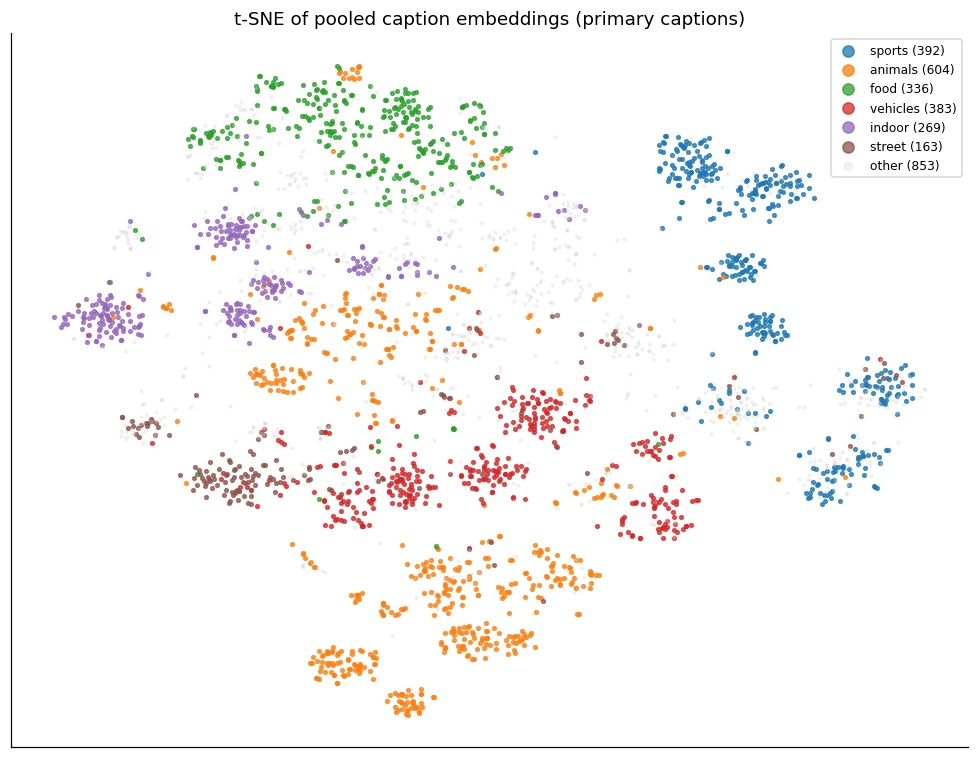

{'other': 853, 'animals': 604, 'sports': 392, 'vehicles': 383, 'food': 336, 'indoor': 269, 'street': 163}


In [33]:
from sklearn.manifold import TSNE

GROUPS = {   # first match wins; a rough semantic label just for colouring the plot
    "sports":   ["tennis", "baseball", "skateboard", "surf", "ski", "snowboard", "frisbee", "kite", "soccer", "racket"],
    "animals":  ["dog", "cat", "horse", "bird", "elephant", "giraffe", "zebra", "sheep", "cow", "bear", "animal"],
    "food":     ["pizza", "sandwich", "cake", "food", "plate", "donut", "banana", "broccoli", "meal", "fruit", "dish"],
    "vehicles": ["car", "bus", "train", "truck", "airplane", "plane", "motorcycle", "bike", "bicycle", "boat", "jet"],
    "indoor":   ["kitchen", "bathroom", "bedroom", "living room", "toilet", "sink", "couch", "bed", "office", "desk"],
    "street":   ["street", "city", "sign", "traffic", "building", "road"],
}
def group_of(text: str) -> str:
    t = text.lower()
    for g, words in GROUPS.items():
        if any(re.search(rf"\b{re.escape(w)}s?\b", t) for w in words):
            return g
    return "other"

cand_df["group"] = cand_df.text.map(group_of)
xy = TSNE(n_components=2, perplexity=30, init="pca", random_state=CFG.seed).fit_transform(pooled_prim.numpy())

fig, ax = plt.subplots(figsize=(9, 7))
palette = dict(zip(list(GROUPS) + ["other"], plt.cm.tab10.colors))
for g, c in palette.items():
    m = (cand_df.group == g).values
    ax.scatter(xy[m, 0], xy[m, 1], s=6 if g != "other" else 3, alpha=.75 if g != "other" else .25,
               color=c if g != "other" else "lightgray", label=f"{g} ({m.sum()})")
ax.set(title="t-SNE of pooled caption embeddings (primary captions)", xticks=[], yticks=[])
ax.legend(markerscale=3, fontsize=8, loc="best"); plt.tight_layout(); savefig("10_tsne"); plt.show()
print(cand_df.group.value_counts().to_dict())

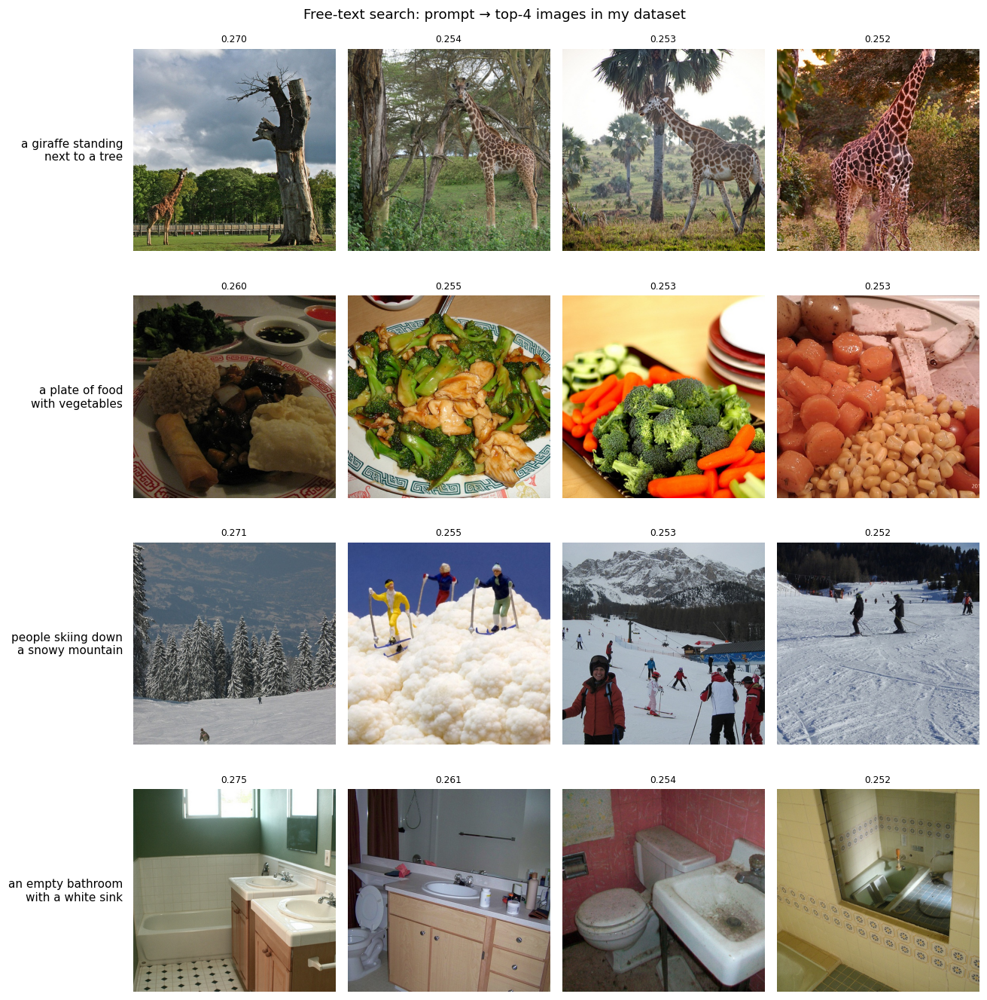

cos('a dog running on the beach', 'a puppy sprinting along the shore') = 0.850
cos('a dog running on the beach', 'a cat sleeping on a sofa') = 0.452
cos('a dog running on the beach', 'a spreadsheet of quarterly revenue') = 0.458


In [34]:
queries = [
    "a giraffe standing next to a tree",
    "a plate of food with vegetables",
    "people skiing down a snowy mountain",
    "an empty bathroom with a white sink",
]
q = text_pipe.encode(queries)["pooled"].float().cpu()
scores = q @ img_emb_final.T
top = scores.topk(4, dim=1)

fig, ax = plt.subplots(len(queries), 4, figsize=(12, 3.1 * len(queries)))
for r, qtext in enumerate(queries):
    for c in range(4):
        k = top.indices[r, c].item()
        ax[r, c].imshow(Image.open(cand_df.proc_path[k])); ax[r, c].axis("off")
        ax[r, c].set_title(f"{top.values[r, c]:.3f}", fontsize=8)
    ax[r, 0].text(-0.05, 0.5, "\n".join(textwrap.wrap(qtext, 18)), transform=ax[r, 0].transAxes,
                  ha="right", va="center", fontsize=10)
plt.suptitle("Free-text search: prompt → top-4 images in my dataset"); plt.tight_layout()
savefig("11_text_search"); plt.show()

pairs_demo = [("a dog running on the beach", "a puppy sprinting along the shore"),
              ("a dog running on the beach", "a cat sleeping on a sofa"),
              ("a dog running on the beach", "a spreadsheet of quarterly revenue")]
emb = {t: text_pipe.encode(t)["pooled"][0] for pair in pairs_demo for t in pair}
for a_, b_ in pairs_demo:
    print(f"cos({a_!r}, {b_!r}) = {F.cosine_similarity(emb[a_], emb[b_], dim=0).item():.3f}")

## 11. End-to-end smoke test with Diffusers

The last check closes the loop across all three libraries: I load the full Stable Diffusion v1.5 pipeline and

1. compare my conditioning with the pipeline's own `encode_prompt()` output, then
2. **generate images by passing my embeddings in through `prompt_embeds=` / `negative_prompt_embeds=`**, bypassing SD's internal text encoding completely.

These images are *not a result*: no training has happened yet, and this is the pretrained model. The point is to show that the tensors my pipeline produces are exactly the interface the diffusion model expects, so Milestone 2 can build on it directly. Needs a GPU (~3.5 GB VRAM in fp16); skipped automatically otherwise.

model_index.json:   0%|          | 0.00/541 [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 15 files:   0%|          | 0/15 [00:00<?, ?it/s]

Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/396 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

vs pipe.encode_prompt(): max |diff| cond = 3.12e-02, uncond = 3.12e-02  (fp16 rounding level)


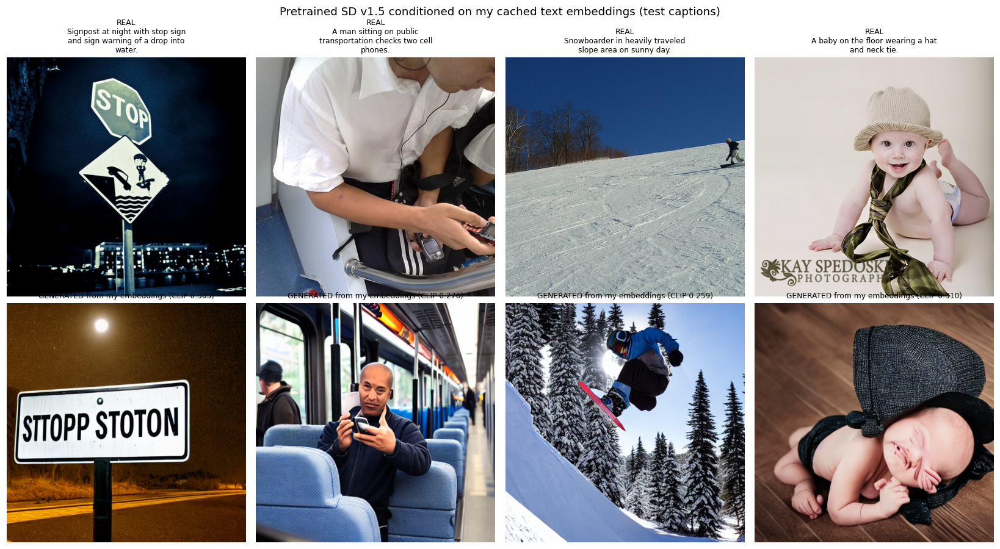

{
  "ran": true,
  "seconds": 14.7,
  "steps": 25,
  "guidance_scale": 7.5,
  "max_diff_vs_encode_prompt": 0.03125,
  "clip_score_generated_mean": 0.2869,
  "clip_score_real_mean": 0.2948
}


In [35]:
GEN_INFO = {"ran": False}
if CFG.run_sd_smoke_test and DEVICE.type == "cuda":
    try:   # fp16 weights are half the download; fall back to full weights if the variant isn't there
        pipe = StableDiffusionPipeline.from_pretrained(CFG.sd_model_id, torch_dtype=torch.float16, variant="fp16")
    except Exception:
        pipe = StableDiffusionPipeline.from_pretrained(CFG.sd_model_id, torch_dtype=torch.float16)
    pipe = pipe.to(DEVICE)
    pipe.set_progress_bar_config(disable=True)

    gen_rows = cand_df[cand_df.split == "test"].sample(4, random_state=CFG.seed).reset_index(drop=True)
    prompts = gen_rows.text.tolist()
    mine = text_pipe.encode(prompts)
    cond = mine["hidden_states"].to(DEVICE, torch.float16)
    neg = uncond_hidden.to(DEVICE, torch.float16).expand(len(prompts), -1, -1)

    ref_cond, ref_neg = pipe.encode_prompt(prompts, device=DEVICE, num_images_per_prompt=1,
                                           do_classifier_free_guidance=True, negative_prompt=[""] * len(prompts))
    d_cond = (ref_cond.float() - cond.float()).abs().max().item()
    d_neg = (ref_neg.float() - neg.float()).abs().max().item()
    print(f"vs pipe.encode_prompt(): max |diff| cond = {d_cond:.2e}, uncond = {d_neg:.2e}  (fp16 rounding level)")

    g = torch.Generator(device=DEVICE).manual_seed(CFG.seed)
    t0 = time.time()
    gen_imgs = pipe(prompt_embeds=cond, negative_prompt_embeds=neg, num_inference_steps=25,
                    guidance_scale=7.5, generator=g).images
    GEN_INFO = {"ran": True, "seconds": round(time.time() - t0, 1), "steps": 25, "guidance_scale": 7.5,
                "max_diff_vs_encode_prompt": d_cond}

    # how well do generated images match their prompts, according to CLIP?
    gen_scores = (embed_pil_images(gen_imgs) * mine["pooled"].float().cpu()).sum(-1)
    GEN_INFO["clip_score_generated_mean"] = round(gen_scores.mean().item(), 4)
    GEN_INFO["clip_score_real_mean"] = round(float(gen_rows.clip_score.mean()), 4)

    fig, ax = plt.subplots(2, 4, figsize=(15, 8.4))
    for k in range(4):
        ax[0, k].imshow(Image.open(gen_rows.proc_path[k])); ax[0, k].axis("off")
        ax[0, k].set_title("REAL\n" + "\n".join(textwrap.wrap(prompts[k], 34)), fontsize=8)
        ax[1, k].imshow(gen_imgs[k]); ax[1, k].axis("off")
        ax[1, k].set_title(f"GENERATED from my embeddings (CLIP {gen_scores[k]:.3f})", fontsize=8)
    plt.suptitle("Pretrained SD v1.5 conditioned on my cached text embeddings (test captions)")
    plt.tight_layout(); savefig("12_sd_smoke_test"); plt.show()
    for k, im in enumerate(gen_imgs):
        im.save(FIG_DIR / f"sd_smoke_{k}.png")
    print(json.dumps(GEN_INFO, indent=2))

    del pipe; torch.cuda.empty_cache()
else:
    print("Skipped: needs a CUDA GPU (or set CFG.run_sd_smoke_test = True).")

## 12. Summary

In [36]:
def folder_size(p: Path) -> float:
    return sum(f.stat().st_size for f in p.rglob("*") if f.is_file()) / 1e6

SUMMARY = {
    "config": asdict(CFG),
    "environment": ENV_INFO,
    "funnel": dict(FUNNEL),
    "dataset": DATASET_STATS,
    "pipeline_checks": {c["check"]: c["passed"] for c in CHECKS},
    "retrieval_test_split": RETRIEVAL.to_dict(orient="index"),
    "sd_smoke_test": GEN_INFO,
    "runtime_minutes": round((time.time() - NOTEBOOK_START) / 60, 1),
}
(ROOT / "milestone1_summary.json").write_text(json.dumps(SUMMARY, indent=2, default=str))

print(f"Runtime: {SUMMARY['runtime_minutes']} min\n")
print("Artifacts:")
for p in [PROC_DIR, EMB_DIR, FIG_DIR, RAW_DIR]:
    print(f"  {str(p):<40} {folder_size(p):9.1f} MB")
for f in ["environment.json", "requirements.txt", "milestone1_summary.json"]:
    print(f"  {str(ROOT / f):<40} {(ROOT / f).stat().st_size / 1e3:9.1f} KB")

print("\nHeadline numbers")
print(f"  pairs: {DATASET_STATS['images']:,} images / {DATASET_STATS['captions']:,} captions | splits {DATASET_STATS['split_counts']}")
print(f"  primary-pair CLIP score: mean {DATASET_STATS['primary_clip_score_mean']}")
print(f"  pipeline checks passed: {sum(c['passed'] for c in CHECKS)}/{len(CHECKS)}")
print(f"  test retrieval text→image: {t2i} | image→text: {i2t}")

Runtime: 21.4 min

Artifacts:
  milestone1_artifacts/processed               356.0 MB
  milestone1_artifacts/embeddings              420.7 MB
  milestone1_artifacts/figures                  15.4 MB
  milestone1_artifacts/raw                     972.6 MB
  milestone1_artifacts/environment.json          0.3 KB
  milestone1_artifacts/requirements.txt          0.2 KB
  milestone1_artifacts/milestone1_summary.json       3.0 KB

Headline numbers
  pairs: 3,000 images / 14,899 captions | splits {'train': 2400, 'test': 300, 'val': 300}
  primary-pair CLIP score: mean 0.2867
  pipeline checks passed: 12/12
  test retrieval text→image: {'R@1': 71.6, 'R@5': 94.48, 'R@10': 98.65} | image→text: {'R@1': 88.0, 'R@5': 99.0, 'R@10': 100.0}


In [ ]:
# Optional: the raw downloads are no longer needed (everything downstream uses processed/ and embeddings/).
# Set to True to free ~0.8 GB. Re-running the notebook will download them again.
DELETE_RAW = False
if DELETE_RAW:
    shutil.rmtree(RAW_DIR, ignore_errors=True)
    print("Deleted raw/")

# Optional (Colab): keep the artifacts after the runtime resets
# from google.colab import drive; drive.mount("/content/drive")
# shutil.copytree(ROOT, "/content/drive/MyDrive/generative_project/milestone1_artifacts", dirs_exist_ok=True)

### Milestone checklist
| Task | Status | Where |
|---|---|---|
| 1. Choose dataset | ✅ MS-COCO 2017 Captions, curated subset; reasoning in Section 2 | §2–3 |
| 2. Clean & preprocess 1k–5k pairs | ✅ ~3,000 images (+ all their clean captions), rule-based + CLIP filtering, 512×512, split 80/10/10, exported in ImageFolder format | §4–7 |
| 3. Environment (PyTorch + Diffusers + CLIP) | ✅ versions logged in `environment.json` / `requirements.txt`; all three libraries exercised together in §11 | §1, §11 |
| 4. Baseline text→embedding notebook | ✅ `TextEmbeddingPipeline`, 12 automated checks incl. exact parity with SD v1.5's encoder, cached embeddings, retrieval / t-SNE / search analysis, end-to-end generation from my embeddings | §8–11 |

### Key decisions and why
* **COCO over Flickr30k:** broader visual content, per-image downloads, and 5 captions per image (which enabled best-caption selection and retrieval evaluation).
* **Two-stage cleaning:** cheap rules first (corrupt files, size, duplicates, malformed text), then a learned filter (CLIP score) for semantic misalignment that rules can't detect. Every rejection is logged with a reason.
* **Primary caption = highest CLIP score**, other captions kept: a clean 1:1 pairing for training, with free caption augmentation available later.
* **`openai/clip-vit-large-patch14` + no attention mask + 77-token padding:** exactly what SD v1.5 expects; verified numerically instead of assumed.
* **Cached fp16 conditioning:** later training can skip the text encoder entirely.

### Limitations I'm aware of
* CLIP filtering inherits CLIP's own biases. It favours captions that name salient objects and can penalize correct but abstract descriptions. I kept the cut conservative (1% of captions, 5% of images) for this reason.
* Center-cropping can remove objects that a caption mentions; the CLIP filter on cropped images reduces but doesn't eliminate this.
* COCO captions are short and literal, so the model won't learn artistic styles from this data.
* The 77-token limit of CLIP is a hard ceiling on prompt detail (not an issue for COCO; max here is well below it).

### Next steps (Milestone 2)
* Build a PyTorch `Dataset` from `metadata.jsonl` (+ random horizontal flip, normalization to [-1, 1]) and pre-encode images to **VAE latents** (64×64×4), just like the text embeddings were cached.
* Fine-tune Stable Diffusion v1.5 with **LoRA** on the U-Net cross-attention layers, using the cached conditioning and ~10% caption dropout (replacing it with the unconditional embedding) so classifier-free guidance keeps working.
* Evaluate on the test split with **CLIP score** and **FID** against the real test images, comparing against the pretrained baseline generated in Section 11.